# **Лабораторная работа №2 Обработка медицинских и рентгеновских снимков**
### **Работу выполнила студентка 2 курса магистратуры группы КомЗр24 Бобина Татьяна Сергеевна**



##Теоретические сведения

## 1. **DICOM**


## 1.1. **Введение в стандарт DICOM**

DICOM (Digital Imaging and Communications in Medicine) - это международный стандарт для управления и передачи медицинских изображений и данных, который используется во многих медицинских учреждениях. Устройства для получения медицинских изображений, такие как магнитно-резонансная томография (МРТ), компьютерная томография (КТ), рентген и ультразвук (УЗИ), используются в радиологии, кардиологии, акушерстве, стоматологии и других областях. [DICOM](https://en.wikipedia.org/w/index.php?title=DICOM&oldid=1044860775) возник на основе стандартов Американского колледжа радиологии и Национальной ассоциации производителей электрооборудования версий 1 и 2. DICOM надежен и используется во всем мире для хранения, обмена, получения, отображения и передачи изображений между устройствами различных производителей.  
В формат DICOM могут быть заключены двух-, трех- или четырехмерные данные визуализации. Кроме того, формат DICOM может хранить множество атрибутов в «тегах», которые включают имя пациента, номер медицинской карты, дату, разрешение и размеры данных визуализации, информацию о сканере, параметры визуализации и т. д. в объекте DICOM. Стандартный список атрибутов в тегах DICOM приведен на сайте Национальной ассоциации производителей электрооборудования (NEMA) [https://www.dicomstandard.org]. Помимо формата DICOM, изображения могут быть сжаты с помощью таких стандартов, как JPEG2000, JPEG без потерь, LZW или run-length encoding. Однако для машинного обучения в медицинской визуализации часто требуются метаданные, чтобы правильно использовать данные, поэтому DICOM является предпочтительным форматом для сохранения данных медицинской визуализации.


## 1.2. **Инструменты визулизации DICOM**

Изображения DICOM необходимо просматривать с помощью специального программного обеспечения, и в этом нет недостатка. В исследовательском сообществе существует несколько инструментов для визуализации, редактирования и анализа данных DICOM. Некоторые из бесплатных и популярных инструментов для редактирования DICOM - [Horos](https://horosproject.org), [Mango](https://ric.uthscsa.edu/mango/mango.html), [3DSlicer](https://www.slicer.org/), [ITKSNAP](https://www.itksnap.org/pmwiki/pmwiki.php), [IrfanView](www.irfanview.com/), [ImageJ](https://imagej.nih.gov/ij/), и [LabelMe](https://labelme2.csail.mit.edu/Release3.0/browserTools/php/publications.php). Рисунок 1 показывет скриншот из программного обеспечения ITK-SNAP.

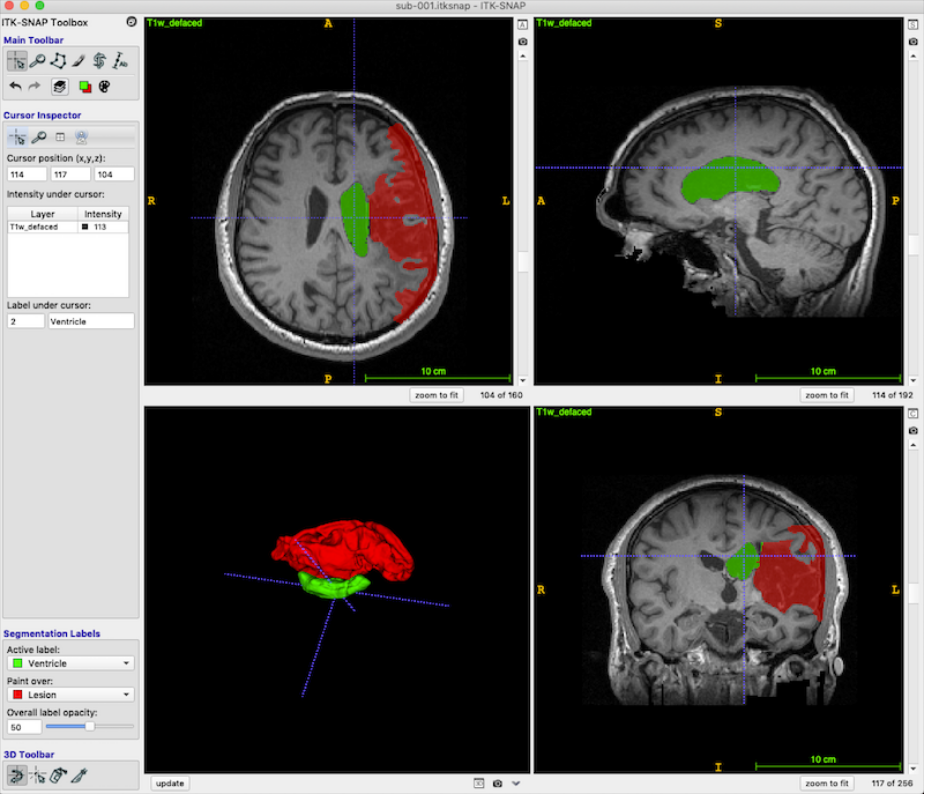

<b>Рисунок 1</b> Визуализация DICOM-данных МРТ с помощью ITK-SNAP</u><br><br>




## 1.3. **Теги DICOM**

DICOM использует формат, основанный на тегах, где каждому элементу метаданных присваивается уникальный идентификатор, определяющий его назначение и размер. Тег начинается с двух компонентов Group и Element. Как следует из названия, группа представляет классы метаданных. Например, группа 0x0010 (по традиции теги DICOM всегда имеют 4-значное шестнадцатеричное значение) содержит информацию о пациенте. Элемент - это более подробная информация в группе. Например, группа 0x0010 и элемент 0x0020 - это номер медицинской карты пациента. Группа и элемент вместе обычно отображаются как (0x0010, 0x0020). Очень хороший сайт для поиска имен тегов - ***dicomlookup.com***. В DICOM существует гораздо больше, чем просто объект изображения, включая методы передачи, объекты преобразования изображений (например, для отображения одного набора на другой), объекты планирования лучевой терапии и даже текстовые объекты отчетности. Здесь также следует отметить, что иногда «тег» относится только к Group:Element, а иногда - к Group:Element и всем метаданным, которые к нему прилагаются - контекст обычно дает это понять.

Как мы уже говорили, стандарт DICOM пользуется огромным успехом, поскольку он обеспечивает комплексную основу для передачи, хранения и печати медицинских изображений. Есть некоторые метаданные DICOM, которые очень важно понимать. Во-первых, в DICOM существует иерархия: пациент / исследование (например, МРТ-исследование) / серия (осевые изображения T1 до контраста) и экземпляр (отдельное изображение). Каждый из них имеет глобальный уникальный идентификатор (UID). Поэтому UID экземпляра серии является наиболее надежным методом сортировки серий. Обратите внимание, что название файла не обязательно отражает конкретного пациента, исследование, серию или изображение. Поэтому распространенной задачей является сортировка всех изображений в серии по расположению срезов, чтобы можно было получить разумное 3D-изображение. Для надежной сортировки файлов определенного типа могут потребоваться следующие объекты: Номер регистрации, Номер эхограммы, Позиция изображения пациента, Тип изображения и другие. Затем можно сложить до семи изображений из серии, чтобы создать одно изображение с семью измерениями. На рисунке 2 показан инкапсулированный тег в файлах DICOM.

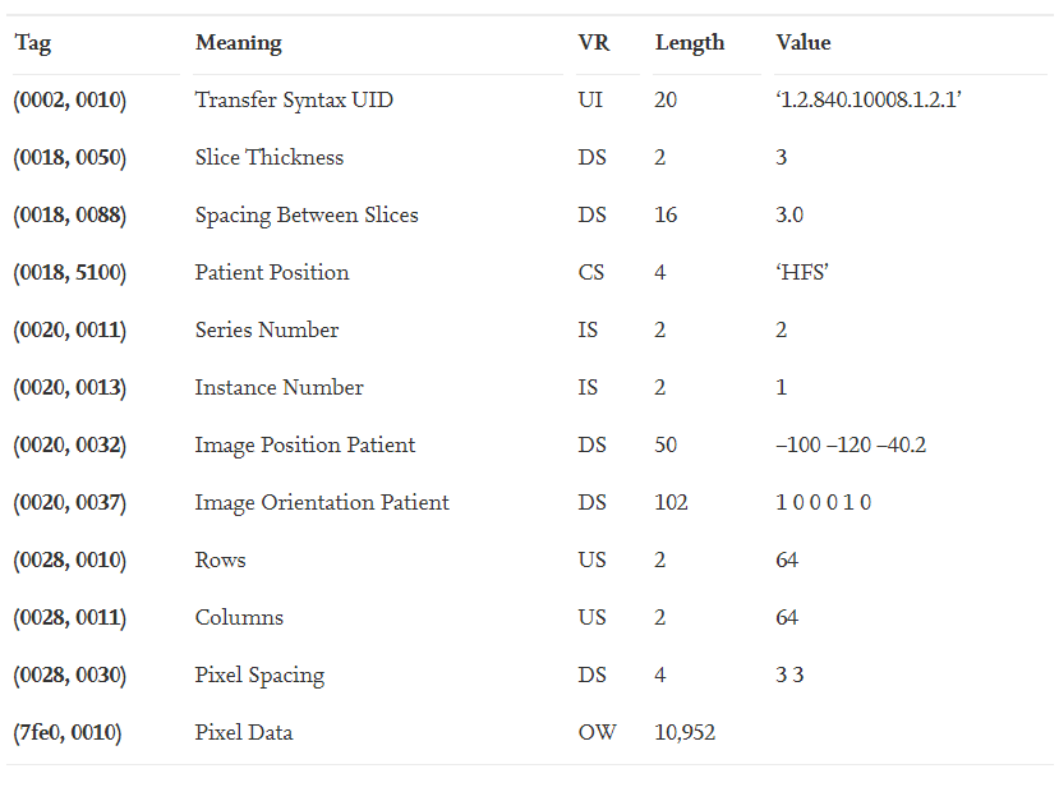

<b>Рисунок 2.</b> Типичные объекты DICOM используются для интерпретации данных изображения и информации, необходимой при конвертации в NIfTI.</u><br><br>




Теперь, когда вы знаете общую концепцию тегов DICOM, необходимо понять некоторые важные нюансы. Как мы уже отмечали выше, тег начинается с описания информации и использует двухчисловой код, который опирается на словарь DICOM. Публичные теги всегда имеют четные значения Group. Производители также могут определять свой частный код, и он всегда должен иметь нечетное значение группы. Второе число в теге после (group,element) - это Value Representation (VR) ([source](https://dicom.nema.org/dicom/2013/output/chtml/part05/sect_6.2.html)), которое определяет тип данных в объекте. В VR используются следующие термины: US = беззнаковые короткие целые числа, DS = десятичная строка, CS = кодовая строка, IS = целочисленная строка, DT = дата-время, OW = другая словесная строка и т. д. Длина определяет количество байт для хранимого значения, а последний компонент столбца является его собственным значением. Второй столбец описывает значение Tag. Обычно DICOM хранит каждый срез отдельно, но есть и другие объекты DICOM, где несколько изображений могут храниться в одном объекте/файле (например, файлы фильмов, которые DICOM обычно называет «многокадровыми»).

## 1.4. **DICOM: Работа в Python**

В python файлы DICOM можно открывать, читать или записывать с помощью библиотеки [Pydicom](https://github.com/pydicom/pydicom) или [SimpleITK](https://github.com/SimpleITK/SimpleITK). Python-код для загрузки и визуализации DICOM-файла и просмотра информации о тегах можно найти здесь.

In [1]:
## DICOM: load data and visualize
!pip install pydicom
!pip install matplotlib

# Import pydicom library
import pydicom as dicom
import matplotlib.pyplot as plt
import gdown
import os

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 37.8 MB/s eta 0:00:00


##Загрузите датасет со снимками DICOM

In [2]:
# Downloading the zip archive containing sample images
if not os.path.isdir("Sampledata_5A"):
    gdown.download(
        "https://drive.google.com/uc?export=download&confirm=pbef&id=1Mafu1sTobziya-n-MFCJeR8QftigKhDG",
        "Sampledata_5A.zip",
        quiet=True,
    )
    !unzip -q Sampledata_5A.zip
    os.remove("Sampledata_5A.zip")

##Прочитайте и визуализируйте изображение

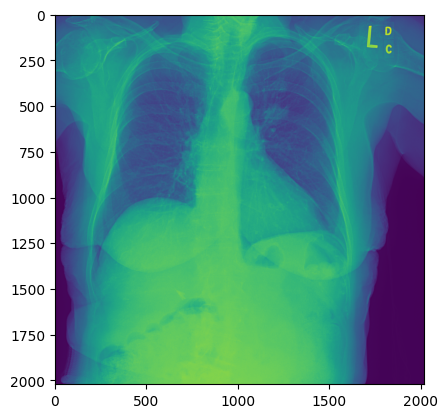

In [3]:
# specify your image path
image_path = "/content/Sampledata_5A/Sample5_1.dcm"

ds = dicom.dcmread(image_path)
plt.imshow(ds.pixel_array)

##Выведите мета-информацию о снимке

In [4]:
## DICOM: metadata info
print(ds)

Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 208
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: Digital X-Ray Image Storage - For Presentation
(0002,0003) Media Storage SOP Instance UID      UI: 1.3.6.1.4.1.14519.5.2.1.6279.6001.307896144859643716158189196068
(0002,0010) Transfer Syntax UID                 UI: Explicit VR Little Endian
(0002,0012) Implementation Class UID            UI: 1.3.6.1.4.1.22213.1.143
(0002,0013) Implementation Version Name         SH: '0.5'
(0002,0016) Source Application Entity Title     AE: 'POSDA'
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 100'
(0008,0008) Image Type                          CS: ['ORIGINAL', 'PRIMARY', '']
(0008,0016) SOP Class UID                       UI: Digital X-Ray Image Storage - For Presentation
(0008,0018) SOP Instance UID                    

##Работа с мета-информацией

In [5]:
# Viewing Field field tag name or tag number
print(ds.ManufacturerModelName)  # to print manufacturer model name
print(ds[0x10, 0x10])  # for patient name use  'print(ds.PatientName)' or tag number

Revolution XQi ADS_28.2
(0010,0010) Patient's Name                      PN: ''


In [6]:
# The field can be printed with part of file name
# for example, find tag name with ‘pat’ as part of name.
ds.dir("pat")

['DistanceSourceToPatient',
 'PatientAge',
 'PatientBirthDate',
 'PatientID',
 'PatientIdentityRemoved',
 'PatientName',
 'PatientOrientation',
 'PatientSex']


**Обезличивание:**
В соответствии с Законом США о переносимости и подотчетности медицинского страхования (HIPAA) и Европейскими общими правилами защиты данных (GDPR), защищенная медицинская информация (например, личность пациента) не должна публиковаться. Однако метаданные (заголовок) DICOM, как правило, содержат некоторую идентифицируемую информацию о пациенте. Поэтому необходима надлежащая деидентификация, которая может быть достигнута путем преобразования DICOM в другие форматы и удаления защищенной информации из сохраненного файла.

##**Задание 1**
Ознакомьтесь подробнее с мета-информацией для представленного примера. Опишите имеющиеся данные и сделайте по ним заключения

In [ ]:
##ваш ответ словарь что означает

Расшифровка наиболее важных тегов, которые помогут понять снимок:



(0008, 0060)	Modality	DX	Модальность: Рентгенография (Digital X-Ray). Это стандартный рентгеновский снимок.


(0018, 0015)	Body Part Examined	CHEST	Исследуемая область тела: Грудная клетка. Это рентген органов грудной клетки.


(0010, 0020)	Patient ID	LIDC-IDRI-0001	Идентификатор пациента: Указывает на то, что снимок взят из публичного набора данных LIDC-IDRI (The Lung Image Database Consortium and Image Database Resource Initiative), который используется для исследований рака легких.


(0012, 0062)	Patient Identity Removed	YES	Идентификационные данные пациента удалены: Подтверждает, что данные были обезличены.


(0012, 0063)	De-identification Method	DCM:113100/...	Метод обезличивания: Был использован стандартный метод обезличивания, определенный в стандарте DICOM.


(0008, 0070)	Manufacturer	GE MEDICAL SYSTEMS	Производитель оборудования: Аппарат произведен компанией General Electric.


(0008, 1090)	Manufacturer's Model Name	Revolution XQi ADS_28.2	Модель оборудования: Рентгеновская система Revolution XQi.


(0028, 0010)	Rows	2022	Высота изображения: Изображение имеет 2022 пикселя по вертикали.


(0028, 0011)	Columns	2022	Ширина изображения: Изображение имеет 2022 пикселя по горизонтали. Это означает, что снимок очень детальный (высокого разрешения).


(0028, 0101)	Bits Stored	14	Битов на пиксель: Для хранения каждого пикселя используется 14 бит. Это означает, что изображение может отображать 2^14 = 16,384 оттенка серого, что обеспечивает высокую контрастность и детализацию.


(0028, 1052)	Rescale Intercept	0	Интерцепт (смещение) для пересчета: Значение 0 означает, что сырые данные пикселей не имеют специального смещения.


(0028, 1053)	Rescale Slope	1	Наклон для пересчета: Значение 1 означает, что сырые данные пикселей напрямую соответствуют их визуальному представлению (без масштабирования).


(0028, 1050)	Window Center	-600	Центр окна (уровень): Один из параметров настройки яркости/контраста при отображении. Типичное значение для рентгена грудной клетки.


(0028, 1051)	Window Width	1600	Ширина окна (контраст): Второй параметр настройки контраста. Широкая ширина окна позволяет одновременно видеть и ткани легких, и кости.


(0018, 0060)	KVP	125	Напряжение на трубке (кВ): Рентгеновская трубка работала при напряжении 125 кВ. Это высокое напряжение, характерное для рентгена грудной клетки, позволяющее "пробить" плотные ткани.


(0018, 1150)	Exposure Time	7	Время экспозиции (мс): Время облучения составило 7 миллисекунд.


(0018, 1151)	X-Ray Tube Current	320	Ток трубки (мА): Сила тока рентгеновской трубки составила 320 мА.


(0008, 0020)	Study Date	20000101	Дата исследования: 01 января 2000 года. Это явно фиктивная дата, установленная в процессе обезличивания данных.


# 2. **NIfTI**

## 2.1. **Введение в NIfTI**

Несмотря на то, что DICOM - очень гибкая и всеобъемлющая система, это распространенная проблема в исследовательских средах, усугубляемая методами анализа и постоянным ростом данных. Формат Neuroimaging Informatics Technology Initiative (NIfTI) отличается от DICOM тем, что это очень минималистичный формат. Метаданные DICOM часто удаляются или преобразуются в NIfTI, который сохраняет информацию о размере вокселя и положении пациента. Полное удаление метаданных DICOM для исследований с открытым исходным кодом позволило бы избежать проблем с конфиденциальностью, но при этом была бы удалена часть важной информации, необходимой для алгоритмов искусственного интеллекта. Ученые, работающие в области нейровизуализации, в основном используют формат NIfTI для хранения и передачи данных клинической визуализации. Они могут смешивать и сочетать инструменты обработки и анализа изображений, разработанные разными командами, используя формат NIfTI, широко распространенный в исследованиях в области нейровизуализации.



## 2.2. **Конвертация из DICOM в NIfTI**

DICOM является всеобъемлющим и ориентированным на клиническую практику, в то время как NIfTI прост и удобен для исследований. DICOM имеет сложный формат для поддержки всех клинических сценариев и устройств визуализации, которые могут встречаться в медицине. Со временем появились различные версии, а для новых и инновационных методов важная информация об изображениях может еще не иметь утвержденных стандартов DICOM. В связи с этим информация должна храниться в закрытых тегах, что затрудняет преобразование их в NIfTI одним инструментом. Тем не менее, преобразование изображений из сложного формата DICOM в формат NIfTI крайне важно для эффективной обработки данных. Несколько факторов могут нарушить этот процесс ([источник](https://doi.org/10.1016/j.jneumeth.2016.03.001)).

По словам создателей, формат NIfTI изначально задумывался как обратно совместимое расширение фирменного формата файлов ANALYZE-7.5. Перед преобразованием DICOM-файл должен быть рассортирован на различные серии. Под «серией DICOM» понимается коллекция DICOM-изображений (Instances), полученных с одинаковыми свойствами изображения (есть некоторые исключения, когда связанные наборы изображений для каждого места получаются вместе), охватывающих область тела во время исследования ([источник](https://doi.org/10.1007/s10278-013-9657-9)). Большинство изображений получают в формате 2D (опять же, за некоторыми исключениями), но когда они преобразуются в NIfTI, обычно все изображения складываются вместе, чтобы получить объемные 3D-данные. Самый надежный способ сортировки серии DICOM-изображений - найти UID серии, поскольку он должен быть глобально уникальным - ни одно изображение не должно иметь такой UID серии. Некоторые из популярных инструментов преобразования DICOM в NIfTI - [MRIConverter](https://lcni.uoregon.edu/downloads/mriconvert) и [MRIcron](https://www.nitrc.org/projects/mricron), а также [dcm2nii](https://people.cas.sc.edu/rorden/mricron/dcm2nii.html), Pydicom и SimpleITK - python-библиотеки (пример показан здесь), которые напрямую конвертируют и сохраняют DICOM в формат NIfTI вместе с важными метаданными о размере и геометрии пикселя. Программное обеспечение [MRIcro](https://people.cas.sc.edu/rorden/mricro/mricro.html) используется не только для преобразования DICOM в NIfTI, но и для преобразования ITK MetaImage, AFNI, Freesurfer и растровых изображений (PNG, JPEG и т. д.) в NIfTI. По умолчанию SimpleITK сохраняет пиксельное разрешение. Однако pydicom и dcm2niix требуют информацию о пикселях при записи данных в формат NIfTI. Расстояние между пикселями заключено в аффинной матрице, матрице 4x4, которая также сохраняется в формате NIfTI вместе с данными визуализации. Данные NIfTI не могут быть сохранены в виде целых чисел, и даже двоичные файлы масок должны быть преобразованы в 'float32' или 'float64' перед их сохранением в NIfTI. В следующем разделе мы рассмотрим более подробную информацию об аффинных матрицах.

Важная задача, которую решают эти конвертеры, - распознавание тега 'Slice location' в DICOM, чтобы определить, где находится данный срез. После получения всех местоположений срезов они сортируются по местоположению, чтобы получить правильное 3D-представление.

 **Примечание: имена файлов DICOM совершенно произвольны, и на них нельзя полагаться, чтобы определить пациента, исследование, серию или местоположение. Для получения достоверной информации необходимо смотреть на теги DICOM.**

##Работа с DICOM и NIfTI

In [7]:
# Use SimpleITK or pydicom to convert DICOM into NIfTI. And nibabel can be used to work with NIfTI format
!pip install SimpleITK
!pip install nibabel
!pip install numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.6/52.6 MB 18.5 MB/s eta 0:00:00


In [8]:
!pip install pydicom SimpleITK nibabel numpy matplotlib

In [9]:
## DICOM to NIfTI with SimpleITK/pydicom
import SimpleITK as sitk
import pydicom
import nibabel as nib
import numpy as np
import os
import matplotlib.pyplot as plt
import pydicom as dicom

##Сконвертируйте DICOM файл в NIfTI

In [10]:
dicom_path = "/content/Sampledata_5A/"

for each in os.listdir(dicom_path):
    if ".nii" not in each:
        print(each)
        imgObj = sitk.ReadImage(os.path.join(dicom_path, each))
        ndarray = sitk.GetArrayFromImage(imgObj)
        writeObj = sitk.GetImageFromArray(ndarray)
        writeObj.CopyInformation(imgObj)
        writer = sitk.ImageFileWriter()
        writer.SetFileName(dicom_path + each + ".nii.gz")
        writer.Execute(writeObj)
        print([each, "done"])

        # OR pydicom for reading dicom files
        # imgObj=pydicom.dcmread(filepath)
        # ndarray=imgObj.pixel_array
        # newImgObj=nib.Nifti1Image(ndarray,affine)
        # nib.save(newImgObj,dicom_path+each+'.nii.gz')
        # убрали честь информации, стало меньше весить

Sample5_1.dcm
['Sample5_1.dcm', 'done']


## 2.3. **Работа со снимками стандарта NIfTI**

Формат NIfTI может сохранять данные заголовка и изображения отдельно, хотя обычно они хранятся в одном файле. Для чтения изображений NIfTI, а также для записи изображений в формате NIfTI с помощью Python ('import nibabel') обычно используется программа NiBabel. Файлы NIfTI обычно заканчиваются расширением '.nii' и могут быть сжаты с помощью gzip (это расширение '.nii.gz'). Существуют форматы 'NIfTI-1' и 'NIfTI-2', последний позволяет хранить больше данных. Скрипт на языке Python по загрузке и записи файлов NIfTI, извлечению заголовочной информации и извлечению аффинов можно найти на сайте [NiBabel](https://nipy.org/nibabel/nifti_images.html), некоторые из них также приведены здесь.

##Проанализируйте полученный снимок формата NIfTI

In [11]:
## Working with NIfTI
# Import nibabel, load NIfTI and extract header information

Nifti_path = "/content/Sampledata_5A/"
example_ni1 = os.path.join(Nifti_path, "Sample5_1.dcm.nii.gz")
n1_img = nib.load(example_ni1)

# NIfTI header
n1_header = n1_img.header
print(n1_header)

<class 'nibabel.nifti1.Nifti1Header'> object, endian='<'
sizeof_hdr      : 348
data_type       : np.bytes_(b'')
db_name         : np.bytes_(b'')
extents         : 0
session_error   : 0
regular         : np.bytes_(b'r')
dim_info        : 0
dim             : [   3 2022 2022    1    1    1    1    1]
intent_p1       : 0.0
intent_p2       : 0.0
intent_p3       : 0.0
intent_code     : none
datatype        : uint16
bitpix          : 16
slice_start     : 0
pixdim          : [1. 1. 1. 1. 0. 0. 0. 0.]
vox_offset      : 0.0
scl_slope       : nan
scl_inter       : nan
slice_end       : 0
slice_code      : unknown
xyzt_units      : 10
cal_max         : 0.0
cal_min         : 0.0
slice_duration  : 0.0
toffset         : 0.0
glmax           : 0
glmin           : 0
descrip         : np.bytes_(b'')
aux_file        : np.bytes_(b'')
qform_code      : scanner
sform_code      : scanner
quatern_b       : 0.0
quatern_c       : 0.0
quatern_d       : 1.0
qoffset_x       : -0.0
qoffset_y       : -0.0
qoffset_z  

In [12]:
# To save array in NIfTI format, it also need affine property to hold it's spatial resolution
# If data stored is in bitmap format, it may not have affine but to save them in NIfTI format, one may create an identity affine matrix.
# 'affine1 = np.eye(4)'

# Save NIfTI after data processing.
affine1 = n1_img.affine
data = n1_img.get_fdata()
# Do normalization or some data processing and save output data.
data2 = nib.Nifti1Image(data, affine1)
nib.save(data2, Nifti_path + "NIfTI_processed.nii.gz")

# 3. **Конвертация DICOM/NIfTI в 2D изображения**

Изображения DICOM или NIfTI часто преобразуются в формат 2D-изображений при использовании моделей машинного обучения. Для 2D-моделей машинного обучения можно использовать 2D-изображения с одним каналом интенсивности серого или трехканальным RGB-изображением. Легко подавать данные в модели машинного обучения на основе PyTorch, если формат данных представляет собой серию двумерных растровых изображений (например, jpeg, png, tiff и т. д.) Фотографические изображения также представлены в формате двумерных изображений и используются в машинном обучении для алгоритмов обучения переносу. Эти данные должны быть введены в модели тем же способом. Растровые изображения можно легко визуализировать на различных платформах с помощью встроенного в систему программного обеспечения для просмотра изображений. Сценарий на языке Python для преобразования DICOM и NIfTI в растровые изображения можно найти здесь.

In [13]:
## Convert the DICOM into png/jpg images
import pydicom as dicom
from PIL import Image

# specify your image path
dicom_image = "/content/Sampledata_5A/Sample5_1.dcm"
ds = dicom.dcmread(dicom_image)

imdata = ds.pixel_array.astype("float32")
print(imdata.shape)
print("max=", np.max(imdata))
print("min=", np.min(imdata))

(2022, 2022)
max= 15563.0
min= 171.0


In [14]:
# Normalize data if neccessary
data = (imdata / np.max(imdata)) * 255

print("Normalized Intensity=", np.min(data), np.max(data))
darray = data.astype("uint8")
im = Image.fromarray(darray)
im.convert("RGB")
im.save(os.path.join(dicom_image[: -len(".dcm")] + ".png"))

Normalized Intensity= 2.8018377 255.0


In [15]:
## Convert the NIfTI into png/jpg images
import nibabel as nib
from PIL import Image

# specify your image path
Nifti_path = "/content/Sampledata_5A/Sample5_1.dcm.nii.gz"
img = nib.load(Nifti_path)  # read nii
img_fdata = img.get_fdata()

print(img_fdata.shape)
img_fdata2 = np.squeeze(img_fdata)
print(img_fdata2.shape)

(2022, 2022, 1)
(2022, 2022)


In [16]:
# Normalize data if neccessary
data2 = (img_fdata2 / np.max(img_fdata2)) * 255
print("Normalized Intensity=", np.min(data2), np.max(data2))

# save in jpg format
darray2 = data2.astype("uint8")
im2 = Image.fromarray(darray2)
im2.convert("RGB")
im2.save(os.path.join(Nifti_path[: -len(".dcm.nii.gz")] + ".jpg"))
print("Nifti file saved in jpg format")

Normalized Intensity= 2.801837691961704 255.0
Nifti file saved in jpg format


## **Задание 2**
Визуализируйте полученные 2D изображения, а также проведите анализ мета-информации, имеющейся в файлах NIfTI.

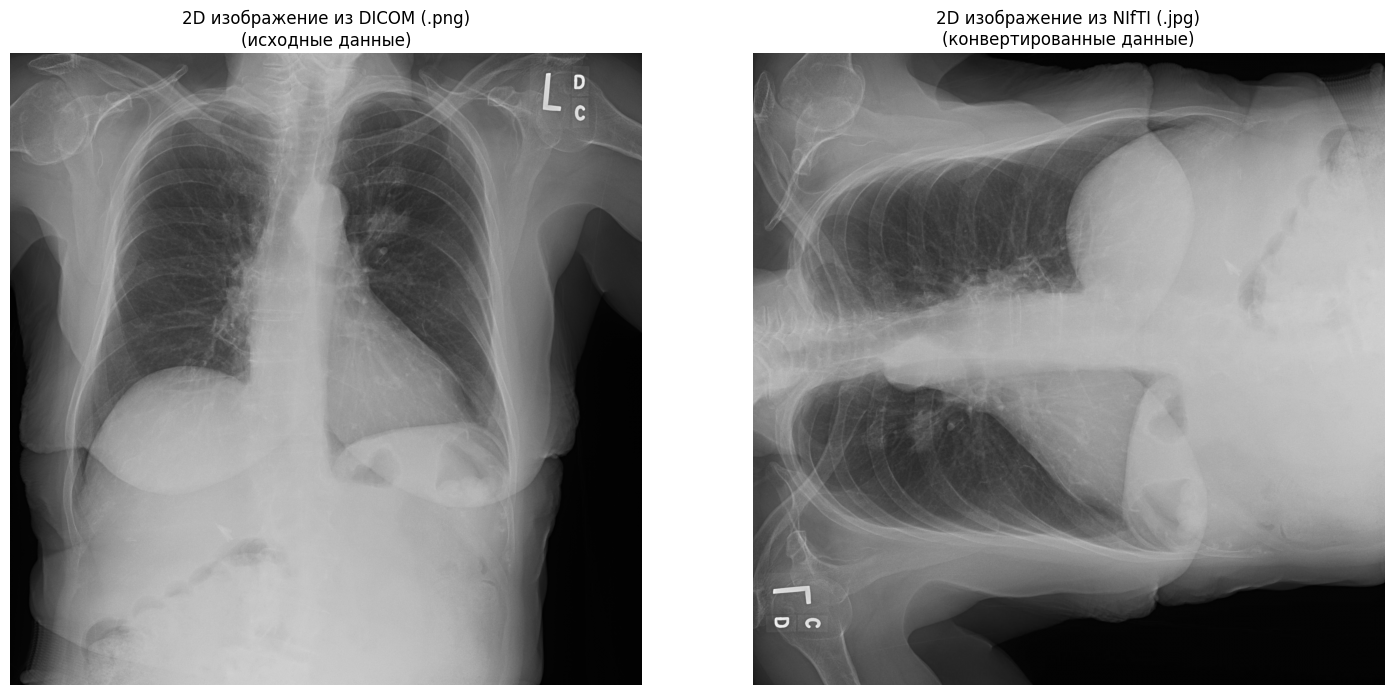

Размер PNG изображения: (2022, 2022)
Размер JPG изображения: (2022, 2022)
Диапазон значений в PNG: [0.007843137718737125, 1.0]
Диапазон значений в JPG: [1, 255]


In [18]:
import matplotlib.pyplot as plt

png_path = "/content/Sampledata_5A/Sample5_1.png"
jpg_path = "/content/Sampledata_5A/Sample5_1.jpg"

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

img_png = plt.imread(png_path)
axes[0].imshow(img_png, cmap='gray')
axes[0].set_title('2D изображение из DICOM (.png)\n(исходные данные)')
axes[0].axis('off')

img_jpg = plt.imread(jpg_path)
axes[1].imshow(img_jpg, cmap='gray')
axes[1].set_title('2D изображение из NIfTI (.jpg)\n(конвертированные данные)')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print(f"Размер PNG изображения: {img_png.shape}")
print(f"Размер JPG изображения: {img_jpg.shape}")
print(f"Диапазон значений в PNG: [{img_png.min()}, {img_png.max()}]")
print(f"Диапазон значений в JPG: [{img_jpg.min()}, {img_jpg.max()}]")

In [23]:
import nibabel as nib
import numpy as np

Nifti_path = "/content/Sampledata_5A/Sample5_1.dcm.nii.gz"
n1_img = nib.load(Nifti_path)
n1_header = n1_img.header

print(f"Класс заголовка: {type(n1_header)}")
print(f"Размер заголовка: {n1_header['sizeof_hdr']} байт")

dimensions = n1_header['dim']
print(f"Массив размерности (dim): {dimensions}")
print(f"Количество измерений: {dimensions[0]}")
print(f"Ширина (X-ось): {dimensions[1]} пикселей")
print(f"Высота (Y-ось): {dimensions[2]} пикселей")
print(f"Глубина (Z-ось): {dimensions[3]} срезов")
print(f"Время (t-ось): {dimensions[4]} временных точек")

data = n1_img.get_fdata()
print(f"\nФактическая форма данных: {data.shape}")
print(f"Тип данных массива: {data.dtype}")

pixdim = n1_header['pixdim']
print(f"Физические размеры вокселей (pixdim): {pixdim}")
print(f"Размер по X: {pixdim[1]} мм")
print(f"Размер по Y: {pixdim[2]} мм")
print(f"Размер по Z: {pixdim[3]} мм")
print(f"Размер по времени: {pixdim[4]} сек")

xyzt_units = n1_header['xyzt_units']
print(f"Единицы измерения: {xyzt_units}")
print(f"Пространственные единицы: {xyzt_units & 0x7}")
print(f"Временные единицы: {(xyzt_units >> 3) & 0x7}")

affine = n1_img.affine
print(f"\nАффинная матрица преобразования:")
print(affine)

Класс заголовка: <class 'nibabel.nifti1.Nifti1Header'>
Размер заголовка: 348 байт
Массив размерности (dim): [   3 2022 2022    1    1    1    1    1]
Количество измерений: 3
Ширина (X-ось): 2022 пикселей
Высота (Y-ось): 2022 пикселей
Глубина (Z-ось): 1 срезов
Время (t-ось): 1 временных точек

Фактическая форма данных: (2022, 2022, 1)
Тип данных массива: float64
Физические размеры вокселей (pixdim): [1. 1. 1. 1. 0. 0. 0. 0.]
Размер по X: 1.0 мм
Размер по Y: 1.0 мм
Размер по Z: 1.0 мм
Размер по времени: 0.0 сек
Единицы измерения: 10
Пространственные единицы: 2
Временные единицы: 1

Аффинная матрица преобразования:
[[-1.  0.  0. -0.]
 [ 0. -1.  0. -0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]


Вывод:

dim : [ 3 2022 2022 1 1 1 1 1]

Первое значение (3) — количество измерений (3D).

Второе и третье значения (2022, 2022) — это высота и ширина каждого среза.

Четвертое значение (1) — количество срезов. Значение 1 говорит о том, что в этом NIfTI-файле хранится всего один 2D-срез, упакованный в 3D-пространство.

pixdim : [1. 1. 1. 1. 0. 0. 0. 0.] определяет физический размер вокселя (пикселя в 3D) по каждой оси.

pixdim[1], pixdim[2], pixdim[3] — это размер вокселя по осям x, y, z соответственно.

srow_x, srow_y, srow_z

Это аффинная матрица, которая описывает преобразование из координат вокселей (индексов пикселей) в реальные мировые координаты (в миллиметрах).

srow_x: [-1. 0. 0. -0.] — это означает, что ось X в изображении инвертирована (знак -1) относительно оси X сканера. Это обычная практика для медицинских изображений.

srow_y: [ 0. -1. 0. -0.] — ось Y также инвертирована.

srow_z: [0. 0. 1. 0.] — ось Z не изменена.

Матрица является единичной с инверсией по X и Y, что подтверждает отсутствие реальных физических размеров в pixdim.

# 4. **Иные форматы изображений**

Кроме DICOM и NIfTI, существует еще несколько форматов изображений, которые используются время от времени. Эти форматы используются для немедицинских изображений, например фотографий, и обладают гораздо большей совместимостью с немедицинскими инструментами.

[JPEG](https://doi.org/10.2345/0899-8205-43.2.131) (Joint Photographic Experts Group): JPEG - это формат файлов, разработанный Объединенной группой экспертов по фотографии. Формат JPEG поддерживает как сжатие без потерь (обратимое - изображение, полученное после сжатия и распаковки, математически идентично исходному), так и сжатие с потерями (необратимое). Сжатие с потерями используется в стандартном JPEG. Оператор может контролировать «качество», которое, в свою очередь, влияет на объем используемой памяти. Полученное изображение не будет математически идентично оригиналу, но при соответствующем коэффициенте качества разница не будет визуально значимой. Подходящий коэффициент качества зависит от изображения и случая использования, поэтому обычно требуется экспериментировать, но обычно приемлемыми являются значения около 90. JPEG 2000 - это еще одна версия, которая обеспечивает сжатие без потерь и позволяет достичь более высокого коэффициента сжатия при том же качестве изображения, но требует большей вычислительной мощности.

[TIFF](https://doi.org/10.2345/0899-8205-43.2.131) (Tagged Image File Format): TIFF поддерживает сжатие как с потерями, так и без потерь. Он популярен для публикаций, поскольку в нем указывается количество точек на дюйм, что важно для печатных изданий, но не актуально для публикаций в Интернете.

[PNG](https://doi.org/10.2345/0899-8205-43.2.131) (Portable Network Graphics): Этот формат позволяет сжимать изображения без потерь. Он был одним из первых форматов, поддерживающих 16-битные полутоновые изображения, и поэтому популярен в медицинской визуализации, поскольку многие методы исследования также имеют 16-битную полутоновую шкалу.

[GIF](https://doi.org/10.2345/0899-8205-43.2.131) (Graphics Interchange Format): Это был один из первых форматов для работы с изображениями. Однако сейчас он уже не так широко используется. Он предлагает ограниченный набор функций и неэффективное сжатие. Он широко используется для веб-сайтов и обеспечивает сжатие без потерь и прозрачность.

## **Основная часть лабораторной работы**

## **Задание 3**
Загрузите датасет рентгеновских снимков коронавируса и пневмонии (https://www.kaggle.com/datasets/prashant268/chest-xray-covid19-pneumonia). Визуализируйте примеры из разных классов

In [25]:
import os
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import random

In [24]:
##ваш код
import kagglehub

# Download latest version
path = kagglehub.dataset_download("prashant268/chest-xray-covid19-pneumonia")

print("Path to dataset files:", path)

100%|██████████| 2.06G/2.06G [00:25<00:00, 85.2MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/prashant268/chest-xray-covid19-pneumonia/versions/2


In [26]:
def explore_dataset(base_path):
    print("\nСтруктура датасета:")
    for root, dirs, files in os.walk(base_path):
        level = root.replace(base_path, '').count(os.sep)
        indent = ' ' * 2 * level
        print(f"{indent}{os.path.basename(root)}/")
        subindent = ' ' * 2 * (level + 1)
        if level == 1:  # Показываем только первые несколько файлов в каждой категории
            for i, file in enumerate(files[:3]):
                if i == 2 and len(files) > 3:
                    print(f"{subindent}... и еще {len(files) - 3} файлов")
                    break
                print(f"{subindent}{file}")

explore_dataset(path)

def find_classes(base_path):
    classes = []
    for item in os.listdir(base_path):
        item_path = os.path.join(base_path, item)
        if os.path.isdir(item_path) and not item.startswith('.'):
            classes.append(item)
    return classes

classes = find_classes(path)
print(f"\nНайдены классы: {classes}")

def visualize_samples(base_path, classes, num_samples=3):
    fig, axes = plt.subplots(len(classes), num_samples, figsize=(15, 5 * len(classes)))

    if len(classes) == 1:
        axes = [axes]

    for i, class_name in enumerate(classes):
        class_path = os.path.join(base_path, class_name)

        images = [f for f in os.listdir(class_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

        if not images:
            print(f"В классе {class_name} не найдено изображений")
            continue

        sample_images = random.sample(images, min(num_samples, len(images)))

        print(f"\nКласс '{class_name}': {len(images)} изображений")

        for j, img_name in enumerate(sample_images):
            img_path = os.path.join(class_path, img_name)

            try:
                img = Image.open(img_path)
                img_array = np.array(img)

                if len(axes.shape) > 1:
                    ax = axes[i, j]
                else:
                    ax = axes[j]

                ax.imshow(img_array, cmap='gray')
                ax.set_title(f'{class_name}\n{img_name}')
                ax.axis('off')

                print(f"  {img_name}: {img_array.shape}, диапазон [{img_array.min()}-{img_array.max()}]")

            except Exception as e:
                print(f"Ошибка загрузки {img_path}: {e}")

    plt.tight_layout()
    plt.show()

def analyze_class_distribution(base_path, classes):
    print("\nРаспределение по классам:")
    total_images = 0
    class_stats = {}

    for class_name in classes:
        class_path = os.path.join(base_path, class_name)
        images = [f for f in os.listdir(class_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        count = len(images)
        class_stats[class_name] = count
        total_images += count
        print(f"  {class_name}: {count} изображений")

    print(f"Всего изображений: {total_images}")

    plt.figure(figsize=(10, 6))
    plt.bar(class_stats.keys(), class_stats.values())
    plt.title('Распределение изображений по классам')
    plt.xlabel('Классы')
    plt.ylabel('Количество изображений')
    plt.xticks(rotation=45)

    for i, (class_name, count) in enumerate(class_stats.items()):
        plt.text(i, count + 5, str(count), ha='center', va='bottom')

    plt.tight_layout()
    plt.show()

    return class_stats


Структура датасета:
2/
  Data/
    train/
      COVID19/
      PNEUMONIA/
      NORMAL/
    test/
      COVID19/
      PNEUMONIA/
      NORMAL/

Найдены классы: ['Data']


In [27]:
data_path = os.path.join(path, "Data")
print(f"Основной путь к данным: {data_path}")

Основной путь к данным: /root/.cache/kagglehub/datasets/prashant268/chest-xray-covid19-pneumonia/versions/2/Data


In [28]:
def get_actual_classes(data_path, split='train'):
    split_path = os.path.join(data_path, split)
    if os.path.exists(split_path):
        classes = [d for d in os.listdir(split_path)
                  if os.path.isdir(os.path.join(split_path, d)) and not d.startswith('.')]
        return classes, split_path
    return [], None

def analyze_complete_structure(data_path):
    print("\nПОЛНАЯ СТРУКТУРА ДАТАСЕТА:")

    splits = ['train', 'test']
    total_summary = {}

    for split in splits:
        classes, split_path = get_actual_classes(data_path, split)
        if classes:
            print(f"\n{split.upper()}:")
            split_stats = {}

            for class_name in classes:
                class_path = os.path.join(split_path, class_name)
                images = [f for f in os.listdir(class_path)
                         if f.lower().endswith(('.png', '.jpg', '.jpeg', '.jfif'))]
                count = len(images)
                split_stats[class_name] = count
                print(f"  ├── {class_name}: {count} изображений")

                if images:
                    print(f"  │   Примеры: {', '.join(images[:2])}" +
                          (f" ... и еще {len(images)-2}" if len(images) > 2 else ""))

            total_summary[split] = split_stats

    return total_summary

dataset_summary = analyze_complete_structure(data_path)


ПОЛНАЯ СТРУКТУРА ДАТАСЕТА:

TRAIN:
  ├── COVID19: 460 изображений
  │   Примеры: COVID19(242).jpg, COVID19(318).jpg ... и еще 458
  ├── PNEUMONIA: 3418 изображений
  │   Примеры: PNEUMONIA(1085).jpg, PNEUMONIA(2752).jpg ... и еще 3416
  ├── NORMAL: 1266 изображений
  │   Примеры: NORMAL(102).jpg, NORMAL(645).jpg ... и еще 1264

TEST:
  ├── COVID19: 116 изображений
  │   Примеры: COVID19(569).jpg, COVID19(493).jpg ... и еще 114
  ├── PNEUMONIA: 855 изображений
  │   Примеры: PNEUMONIA(3858).jpg, PNEUMONIA(3646).jpg ... и еще 853
  ├── NORMAL: 317 изображений
  │   Примеры: NORMAL(1472).jpg, NORMAL(1397).jpg ... и еще 315


In [29]:
def visualize_actual_samples(data_path, split='train', num_samples=3):

    classes, split_path = get_actual_classes(data_path, split)

    if not classes:
        print(f"Не найдены классы в {split}!")
        return

    print(f"\nВИЗУАЛИЗАЦИЯ КЛАССОВ ИЗ {split.upper()}:")
    print(f"Классы: {classes}")

    fig, axes = plt.subplots(len(classes), num_samples,
                            figsize=(4*num_samples, 4*len(classes)))

    if len(classes) == 1:
        axes = axes.reshape(1, -1)
    elif num_samples == 1:
        axes = axes.reshape(-1, 1)

    for i, class_name in enumerate(classes):
        class_path = os.path.join(split_path, class_name)
        images = [f for f in os.listdir(class_path)
                 if f.lower().endswith(('.png', '.jpg', '.jpeg', '.jfif'))]

        if not images:
            print(f"Нет изображений в классе {class_name}")
            continue

        sample_images = random.sample(images, min(num_samples, len(images)))

        print(f"\nКласс '{class_name}': {len(images)} изображений")

        for j, img_name in enumerate(sample_images):
            img_path = os.path.join(class_path, img_name)

            try:
                img = Image.open(img_path)
                img_array = np.array(img)

                ax = axes[i, j]
                ax.imshow(img_array, cmap='gray')

                color = 'red' if 'COVID' in class_name.upper() else \
                       'orange' if 'PNEUMONIA' in class_name.upper() else 'green'

                ax.set_title(f'{class_name}\n{img_name}',
                           color=color, fontsize=10, pad=5)
                ax.axis('off')

                print(f"  {img_name}: {img_array.shape}, интенс. [{img_array.min()}-{img_array.max()}]")

            except Exception as e:
                print(f"Ошибка загрузки {img_path}: {e}")

    plt.tight_layout()
    plt.suptitle(f'Рентгеновские снимки - {split.upper()} выборка',
                y=1.02, fontsize=14, weight='bold')
    plt.show()


ВИЗУАЛИЗАЦИЯ КЛАССОВ ИЗ TRAIN:
Классы: ['COVID19', 'PNEUMONIA', 'NORMAL']

Класс 'COVID19': 460 изображений
  COVID19(16).jpg: (271, 361, 3), интенс. [0-255]
  COVID19(422).jpg: (2336, 2836, 3), интенс. [0-255]
  COVID19(34).jpg: (1056, 1051, 3), интенс. [0-255]

Класс 'PNEUMONIA': 3418 изображений
  PNEUMONIA(2040).jpg: (680, 920, 3), интенс. [0-255]
  PNEUMONIA(2351).jpg: (728, 1008, 3), интенс. [0-255]
  PNEUMONIA(2902).jpg: (554, 806, 3), интенс. [8-206]

Класс 'NORMAL': 1266 изображений
  NORMAL(190).jpg: (1503, 1800, 3), интенс. [0-255]
  NORMAL(956).jpg: (1982, 2067, 3), интенс. [0-255]
  NORMAL(705).jpg: (1389, 1645, 3), интенс. [0-255]


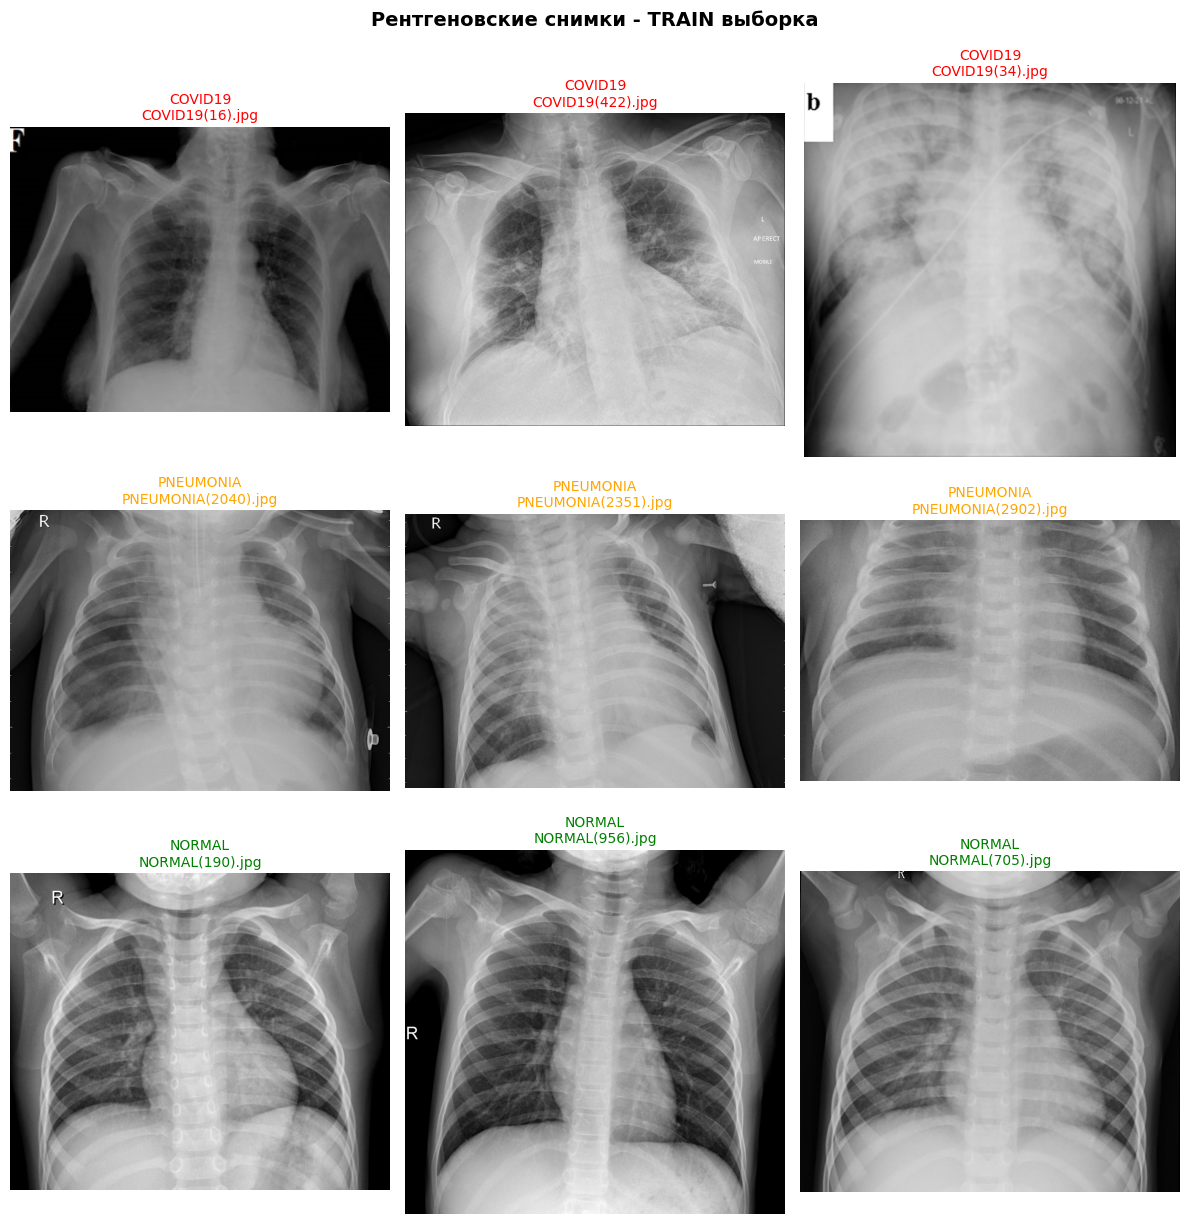


ВИЗУАЛИЗАЦИЯ КЛАССОВ ИЗ TEST:
Классы: ['COVID19', 'PNEUMONIA', 'NORMAL']

Класс 'COVID19': 116 изображений
  COVID19(550).jpg: (2250, 2521, 3), интенс. [0-255]
  COVID19(494).jpg: (2039, 2468, 3), интенс. [0-255]

Класс 'PNEUMONIA': 855 изображений
  PNEUMONIA(4082).jpg: (375, 765, 3), интенс. [19-217]
  PNEUMONIA(3914).jpg: (984, 1520, 3), интенс. [0-255]

Класс 'NORMAL': 317 изображений
  NORMAL(1455).jpg: (1341, 1649, 3), интенс. [0-255]
  NORMAL(1281).jpg: (1233, 1418, 3), интенс. [0-255]


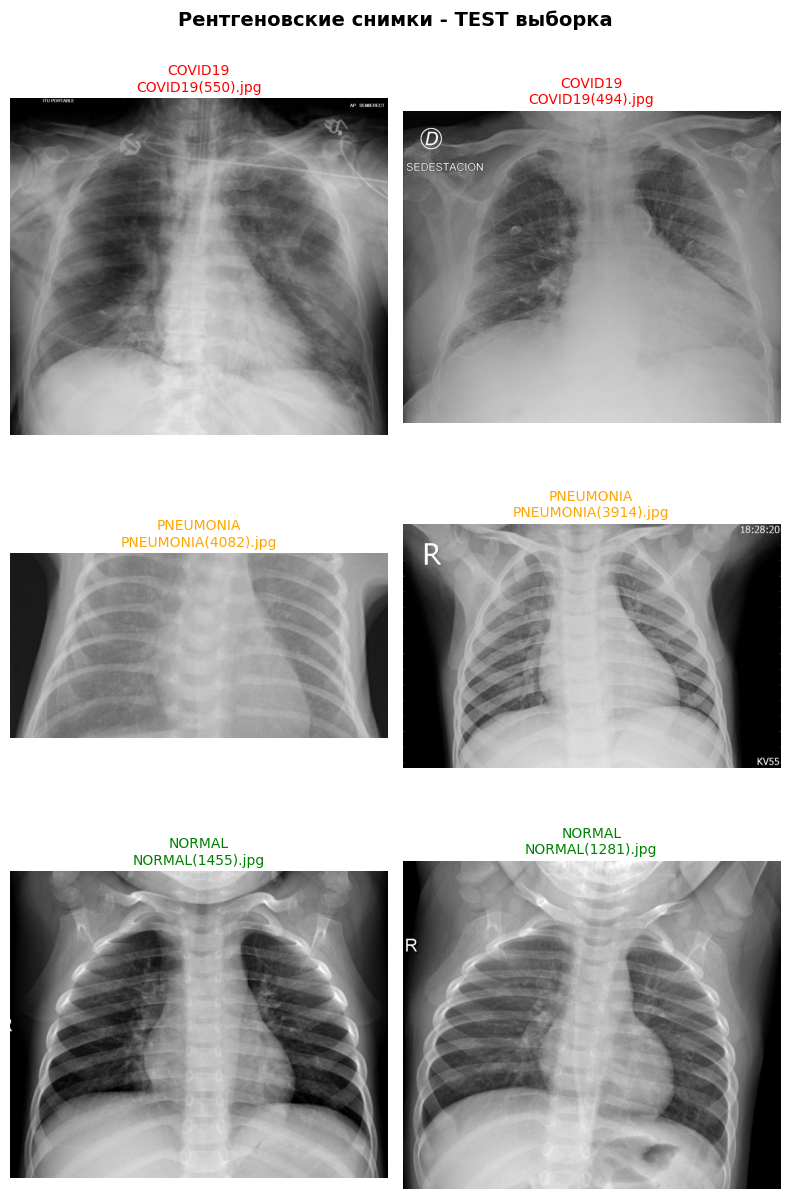

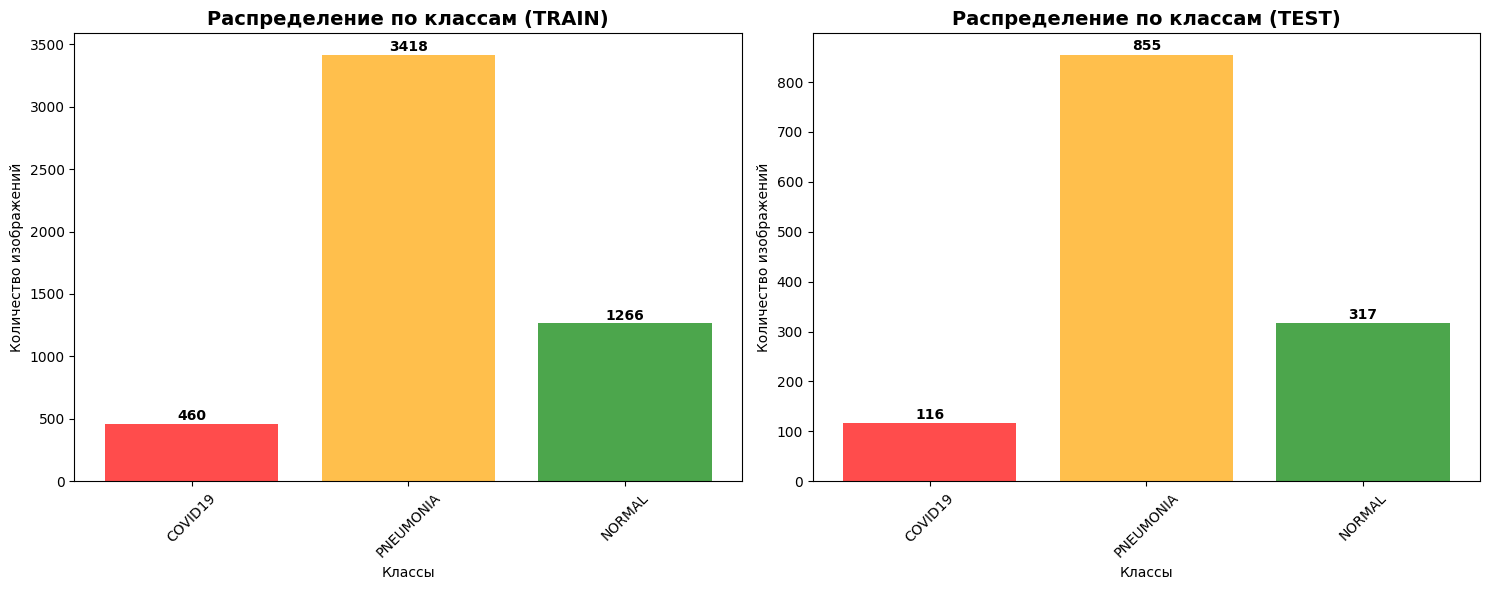

In [31]:
def compare_train_test_distribution(data_path):

    splits = ['train', 'test']
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    for idx, split in enumerate(splits):
        classes, split_path = get_actual_classes(data_path, split)
        if not classes:
            continue

        class_counts = {}
        for class_name in classes:
            class_path = os.path.join(split_path, class_name)
            images = [f for f in os.listdir(class_path)
                     if f.lower().endswith(('.png', '.jpg', '.jpeg', '.jfif'))]
            class_counts[class_name] = len(images)

        colors = []
        for class_name in class_counts.keys():
            if 'COVID' in class_name.upper():
                colors.append('red')
            elif 'PNEUMONIA' in class_name.upper():
                colors.append('orange')
            else:
                colors.append('green')

        bars = axes[idx].bar(class_counts.keys(), class_counts.values(), color=colors, alpha=0.7)
        axes[idx].set_title(f'Распределение по классам ({split.upper()})', fontsize=14, weight='bold')
        axes[idx].set_xlabel('Классы')
        axes[idx].set_ylabel('Количество изображений')
        axes[idx].tick_params(axis='x', rotation=45)

        for bar, count in zip(bars, class_counts.values()):
            height = bar.get_height()
            axes[idx].text(bar.get_x() + bar.get_width()/2., height + 3,
                         f'{count}', ha='center', va='bottom', fontweight='bold')

    plt.tight_layout()
    plt.show()


# Визуализируем train выборку
visualize_actual_samples(data_path, split='train', num_samples=3)

# Визуализируем test выборку
visualize_actual_samples(data_path, split='test', num_samples=2)

# Сравниваем распределение
compare_train_test_distribution(data_path)

##**Задание 4**
Обучите с нуля трех, пяти и десяти слойную сверточную нейронную сеть для классификации рентгеновских снимков легких. Для каждой визуализируйте кривые обучения. Исследуйте эффективность на тестовом датасете в зависимости от количества слоев нейронной сети по метрикам precision, recall и F1-score.

**ВАЖНО:** Не используйте слои батч-нормализации и дроп-аута

In [32]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, precision_recall_fscore_support
import seaborn as sns
import os

In [33]:
##ваш код

def prepare_data(data_path, img_size=(224, 224), batch_size=32):

    train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
        rescale=1./255,
        rotation_range=20,
        width_shift_range=0.2,
        height_shift_range=0.2,
        horizontal_flip=True,
        validation_split=0.2
    )

    test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)

    train_generator = train_datagen.flow_from_directory(
        os.path.join(data_path, 'train'),
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        subset='training',
        shuffle=True
    )

    validation_generator = train_datagen.flow_from_directory(
        os.path.join(data_path, 'train'),
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        subset='validation',
        shuffle=True
    )

    test_generator = test_datagen.flow_from_directory(
        os.path.join(data_path, 'test'),
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=False
    )

    print(f"Классы: {list(train_generator.class_indices.keys())}")
    print(f"Train изображений: {train_generator.samples}")
    print(f"Validation изображений: {validation_generator.samples}")
    print(f"Test изображений: {test_generator.samples}")

    return train_generator, validation_generator, test_generator

# Подготавливаем данные
train_gen, val_gen, test_gen = prepare_data(data_path)

Found 4116 images belonging to 3 classes.
Found 1028 images belonging to 3 classes.
Found 1288 images belonging to 3 classes.
Классы: ['COVID19', 'NORMAL', 'PNEUMONIA']
Train изображений: 4116
Validation изображений: 1028
Test изображений: 1288


In [34]:
# Создание моделей разной глубины
def create_3layer_cnn(input_shape=(224, 224, 3), num_classes=3):
    model = keras.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

def create_5layer_cnn(input_shape=(224, 224, 3), num_classes=3):
    model = keras.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(256, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dense(128, activation='relu'),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

def create_10layer_cnn(input_shape=(224, 224, 3), num_classes=3):
    model = keras.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(256, (3, 3), activation='relu'),
        layers.Conv2D(256, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dense(256, activation='relu'),
        layers.Dense(128, activation='relu'),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

def train_and_visualize(model, model_name, train_gen, val_gen, epochs=15):
    print(f"\nОбучение {model_name}...")

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    history = model.fit(
        train_gen,
        epochs=epochs,
        validation_data=val_gen,
        callbacks=[early_stopping],
        verbose=1
    )

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(history.history['accuracy'], label='Train Accuracy')
    ax1.plot(history.history['val_accuracy'], label='Validation Accuracy')
    ax1.set_title(f'{model_name} - Accuracy')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.plot(history.history['loss'], label='Train Loss')
    ax2.plot(history.history['val_loss'], label='Validation Loss')
    ax2.set_title(f'{model_name} - Loss')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    return history, model

# Функция для оценки модели
def evaluate_model(model, test_gen, model_name, class_names):
    print(f"\nОценка {model_name} на тестовых данных...")

    y_pred = model.predict(test_gen)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true = test_gen.classes

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred_classes, average='weighted'
    )
    accuracy = np.sum(y_pred_classes == y_true) / len(y_true)

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")

    print(f"\nДетальный отчет по классам:")
    print(classification_report(y_true, y_pred_classes, target_names=class_names))

    # Матрица ошибок
    from sklearn.metrics import confusion_matrix
    cm = confusion_matrix(y_true, y_pred_classes)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names,
                yticklabels=class_names)
    plt.title(f'Матрица ошибок - {model_name}')
    plt.xlabel('Предсказанные метки')
    plt.ylabel('Истинные метки')
    plt.show()

    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1_score': f1
    }


Обучение 3-слойная CNN...
Epoch 1/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 115s 865ms/step - accuracy: 0.6943 - loss: 0.6998 - val_accuracy: 0.8142 - val_loss: 0.4604
Epoch 2/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 106s 826ms/step - accuracy: 0.8017 - loss: 0.4484 - val_accuracy: 0.8093 - val_loss: 0.4236
Epoch 3/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 108s 836ms/step - accuracy: 0.8439 - loss: 0.3870 - val_accuracy: 0.8599 - val_loss: 0.3585
Epoch 4/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 108s 835ms/step - accuracy: 0.8646 - loss: 0.3413 - val_accuracy: 0.8327 - val_loss: 0.3963
Epoch 5/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 107s 830ms/step - accuracy: 0.8762 - loss: 0.3238 - val_accuracy: 0.8998 - val_loss: 0.2929


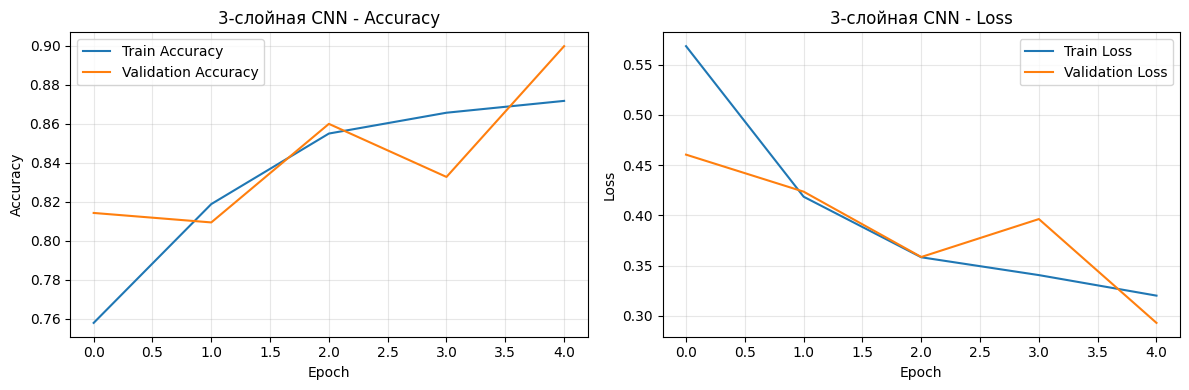


Обучение 5-слойная CNN...
Epoch 1/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 120s 885ms/step - accuracy: 0.6421 - loss: 0.7875 - val_accuracy: 0.7237 - val_loss: 0.5924
Epoch 2/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 108s 841ms/step - accuracy: 0.8123 - loss: 0.4469 - val_accuracy: 0.7996 - val_loss: 0.5443
Epoch 3/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 108s 842ms/step - accuracy: 0.8416 - loss: 0.4095 - val_accuracy: 0.8638 - val_loss: 0.3760
Epoch 4/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 110s 856ms/step - accuracy: 0.8753 - loss: 0.3296 - val_accuracy: 0.8628 - val_loss: 0.3474
Epoch 5/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 111s 864ms/step - accuracy: 0.8805 - loss: 0.3102 - val_accuracy: 0.8755 - val_loss: 0.3682


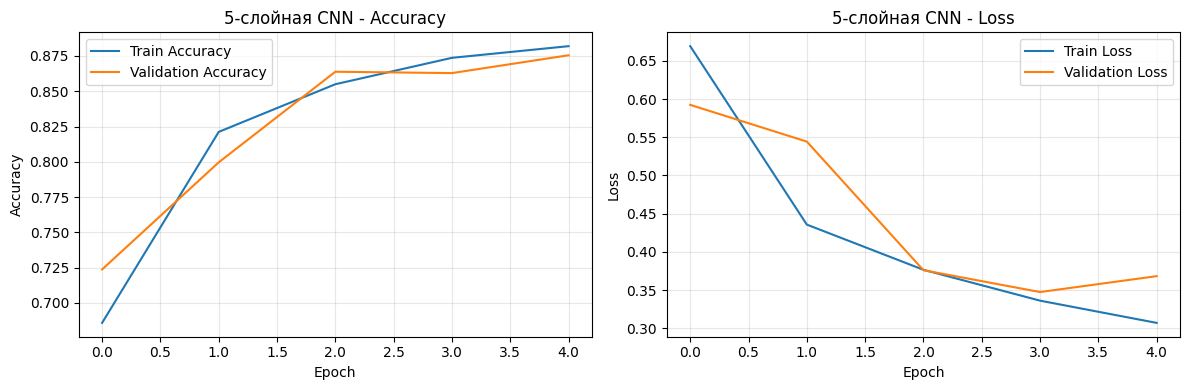


Обучение 10-слойная CNN...
Epoch 1/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 151s 1s/step - accuracy: 0.6405 - loss: 0.8779 - val_accuracy: 0.6644 - val_loss: 0.8622
Epoch 2/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 115s 894ms/step - accuracy: 0.6555 - loss: 0.7380 - val_accuracy: 0.7033 - val_loss: 0.6207
Epoch 3/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 112s 871ms/step - accuracy: 0.6926 - loss: 0.6644 - val_accuracy: 0.7325 - val_loss: 0.7415
Epoch 4/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 111s 863ms/step - accuracy: 0.7399 - loss: 0.6245 - val_accuracy: 0.7831 - val_loss: 0.5809
Epoch 5/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 112s 867ms/step - accuracy: 0.7884 - loss: 0.4731 - val_accuracy: 0.8152 - val_loss: 0.5012


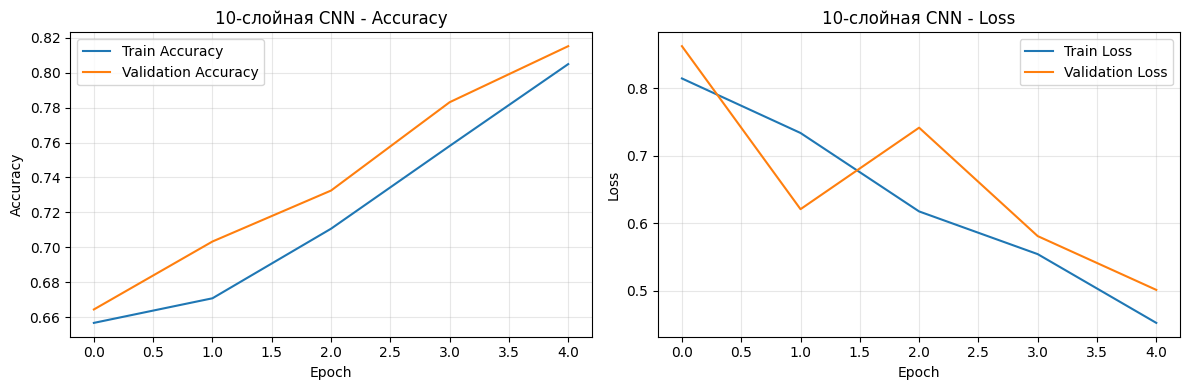

In [36]:
model_3layer = create_3layer_cnn()
model_5layer = create_5layer_cnn()
model_10layer = create_10layer_cnn()

history_3layer, trained_model_3layer = train_and_visualize(
    model_3layer, "3-слойная CNN", train_gen, val_gen, epochs=5
)

history_5layer, trained_model_5layer = train_and_visualize(
    model_5layer, "5-слойная CNN", train_gen, val_gen, epochs=5
)

history_10layer, trained_model_10layer = train_and_visualize(
    model_10layer, "10-слойная CNN", train_gen, val_gen, epochs=5
)


Оценка 3-слойная CNN на тестовых данных...
41/41 ━━━━━━━━━━━━━━━━━━━━ 13s 293ms/step
Accuracy: 0.9224
Precision: 0.9245
Recall: 0.9224
F1-Score: 0.9230

Детальный отчет по классам:
              precision    recall  f1-score   support

     COVID19       0.95      0.91      0.93       116
      NORMAL       0.84      0.90      0.86       317
   PNEUMONIA       0.95      0.93      0.94       855

    accuracy                           0.92      1288
   macro avg       0.91      0.91      0.91      1288
weighted avg       0.92      0.92      0.92      1288



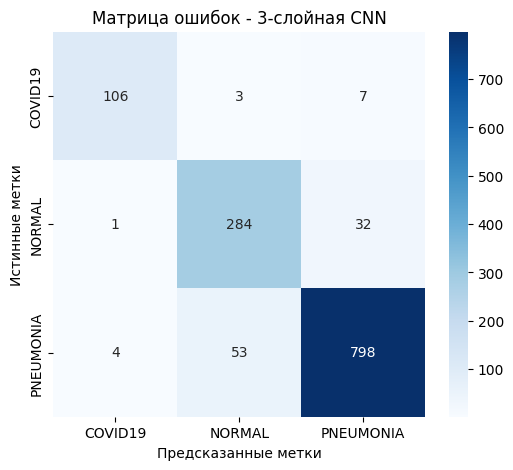


Оценка 5-слойная CNN на тестовых данных...
41/41 ━━━━━━━━━━━━━━━━━━━━ 13s 281ms/step
Accuracy: 0.8502
Precision: 0.8819
Recall: 0.8502
F1-Score: 0.8557

Детальный отчет по классам:
              precision    recall  f1-score   support

     COVID19       0.83      0.81      0.82       116
      NORMAL       0.66      0.95      0.78       317
   PNEUMONIA       0.97      0.82      0.89       855

    accuracy                           0.85      1288
   macro avg       0.82      0.86      0.83      1288
weighted avg       0.88      0.85      0.86      1288



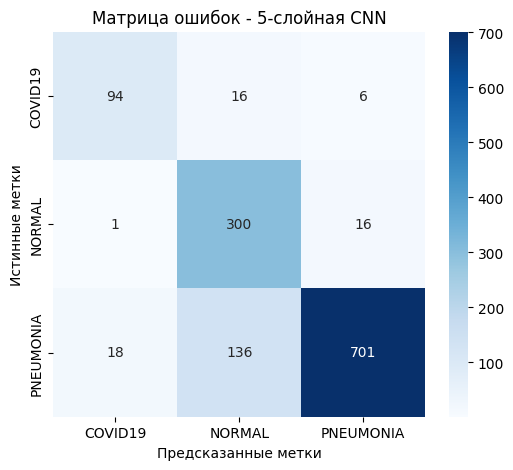


Оценка 10-слойная CNN на тестовых данных...
41/41 ━━━━━━━━━━━━━━━━━━━━ 14s 313ms/step
Accuracy: 0.8641
Precision: 0.8632
Recall: 0.8641
F1-Score: 0.8628

Детальный отчет по классам:
              precision    recall  f1-score   support

     COVID19       0.88      0.72      0.80       116
      NORMAL       0.76      0.75      0.76       317
   PNEUMONIA       0.90      0.93      0.91       855

    accuracy                           0.86      1288
   macro avg       0.85      0.80      0.82      1288
weighted avg       0.86      0.86      0.86      1288



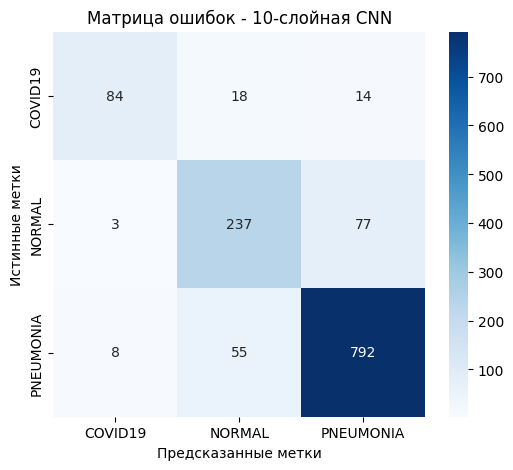


Сравнительный анализ метрик


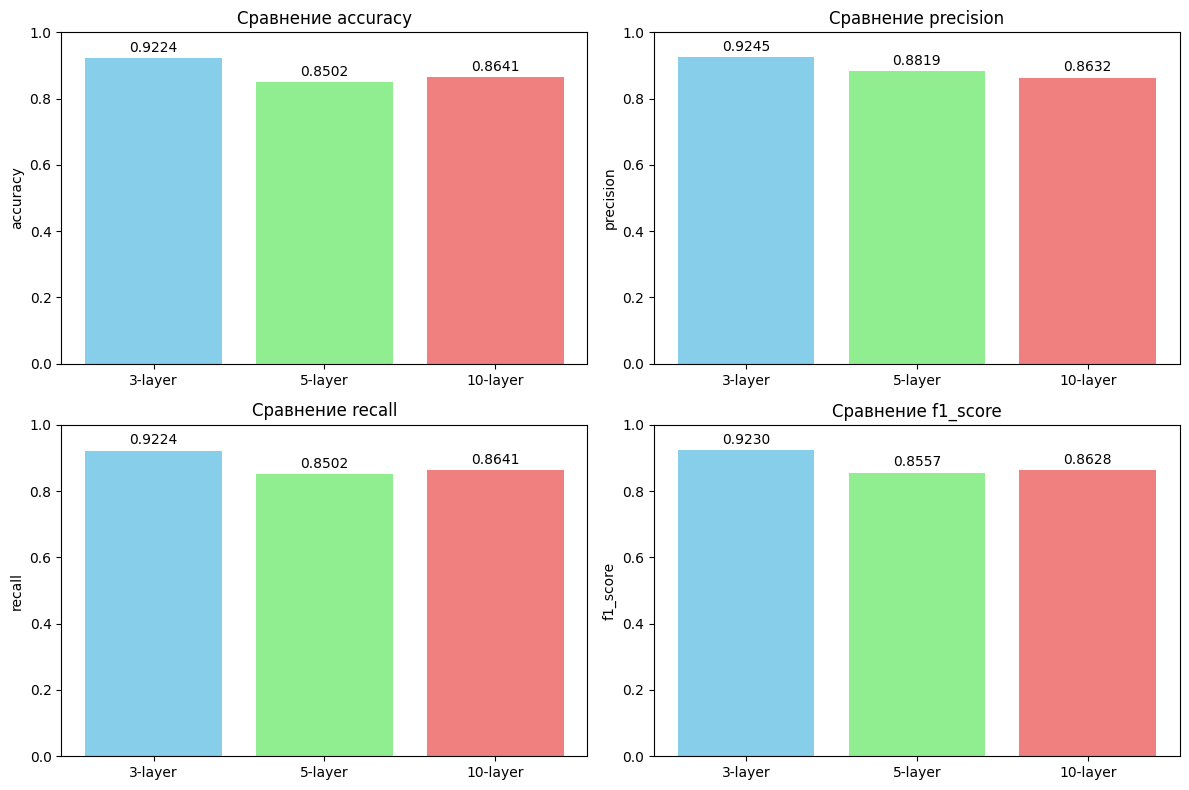

Лучшая модель: 3-layer
F1-Score: 0.9230
Accuracy: 0.9224
Precision: 0.9245
Recall: 0.9224


In [38]:
# Оценка всех моделей

class_names = list(train_gen.class_indices.keys())
results = {}

results['3-layer'] = evaluate_model(trained_model_3layer, test_gen, "3-слойная CNN", class_names)
results['5-layer'] = evaluate_model(trained_model_5layer, test_gen, "5-слойная CNN", class_names)
results['10-layer'] = evaluate_model(trained_model_10layer, test_gen, "10-слойная CNN", class_names)

print("\nСравнительный анализ метрик")
models = list(results.keys())
metrics = ['accuracy', 'precision', 'recall', 'f1_score']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for idx, metric in enumerate(metrics):
    values = [results[model][metric] for model in models]

    bars = axes[idx].bar(models, values, color=['skyblue', 'lightgreen', 'lightcoral'])
    axes[idx].set_title(f'Сравнение {metric}')
    axes[idx].set_ylabel(metric)
    axes[idx].set_ylim(0, 1)

    for bar, value in zip(bars, values):
        height = bar.get_height()
        axes[idx].text(bar.get_x() + bar.get_width()/2., height + 0.01,
                     f'{value:.4f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

best_model = max(results.items(), key=lambda x: x[1]['f1_score'])

print(f"Лучшая модель: {best_model[0]}")
print(f"F1-Score: {best_model[1]['f1_score']:.4f}")
print(f"Accuracy: {best_model[1]['accuracy']:.4f}")
print(f"Precision: {best_model[1]['precision']:.4f}")
print(f"Recall: {best_model[1]['recall']:.4f}")

##**Задание 5**
Добавьте слои батч-нормализации в созданные ранее архитектуры. Сравните результаты на тестовой выборке

In [39]:
##ваш код
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, precision_recall_fscore_support
import seaborn as sns

def create_3layer_cnn_bn(input_shape=(224, 224, 3), num_classes=3):
    model = keras.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.BatchNormalization(),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

def create_5layer_cnn_bn(input_shape=(224, 224, 3), num_classes=3):
    model = keras.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(256, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

def create_10layer_cnn_bn(input_shape=(224, 224, 3), num_classes=3):
    model = keras.Sequential([
        # Блок 1
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Блок 2
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Блок 3
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Блок 4
        layers.Conv2D(256, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(256, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

def train_and_visualize_bn(model, model_name, train_gen, val_gen, epochs=15):
    print(f"\nОбучение {model_name} с BatchNorm...")

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    history = model.fit(
        train_gen,
        epochs=epochs,
        validation_data=val_gen,
        callbacks=[early_stopping],
        verbose=1
    )

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(history.history['accuracy'], label='Train Accuracy')
    ax1.plot(history.history['val_accuracy'], label='Validation Accuracy')
    ax1.set_title(f'{model_name} - Accuracy')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.plot(history.history['loss'], label='Train Loss')
    ax2.plot(history.history['val_loss'], label='Validation Loss')
    ax2.set_title(f'{model_name} - Loss')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    return history, model


Обучение 3-слойная CNN с BN с BatchNorm...
Epoch 1/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 118s 868ms/step - accuracy: 0.7248 - loss: 0.7923 - val_accuracy: 0.1936 - val_loss: 2.1918
Epoch 2/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 132s 1s/step - accuracy: 0.8623 - loss: 0.3962 - val_accuracy: 0.5506 - val_loss: 1.1790
Epoch 3/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 114s 886ms/step - accuracy: 0.8714 - loss: 0.3461 - val_accuracy: 0.7305 - val_loss: 1.5138
Epoch 4/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 107s 829ms/step - accuracy: 0.8840 - loss: 0.3022 - val_accuracy: 0.7451 - val_loss: 0.7662
Epoch 5/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 107s 829ms/step - accuracy: 0.8921 - loss: 0.2809 - val_accuracy: 0.7296 - val_loss: 1.0327


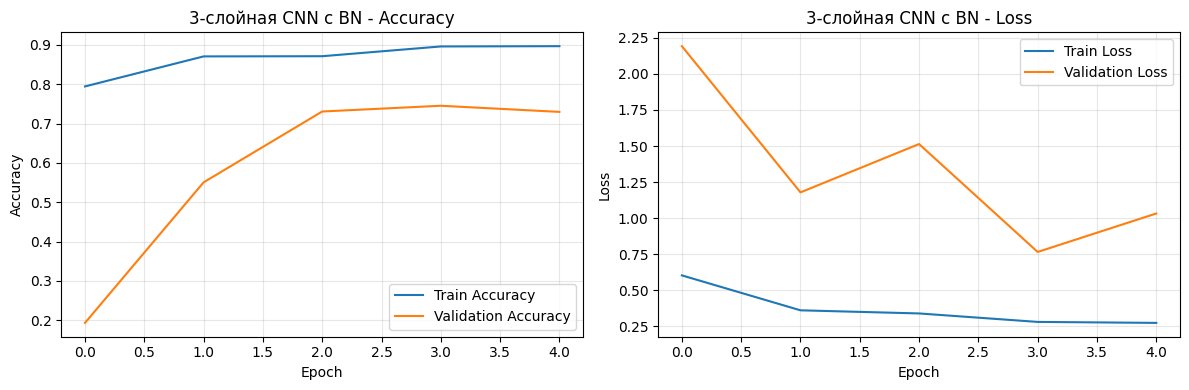


Обучение 5-слойная CNN с BN с BatchNorm...
Epoch 1/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 121s 868ms/step - accuracy: 0.7402 - loss: 0.7930 - val_accuracy: 0.0895 - val_loss: 2.9198
Epoch 2/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 128s 991ms/step - accuracy: 0.8729 - loss: 0.3686 - val_accuracy: 0.0992 - val_loss: 2.7896
Epoch 3/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 106s 825ms/step - accuracy: 0.8862 - loss: 0.3142 - val_accuracy: 0.7121 - val_loss: 1.6388
Epoch 4/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 106s 826ms/step - accuracy: 0.9005 - loss: 0.2590 - val_accuracy: 0.7043 - val_loss: 2.0284
Epoch 5/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 141s 824ms/step - accuracy: 0.9039 - loss: 0.2568 - val_accuracy: 0.3249 - val_loss: 5.5660


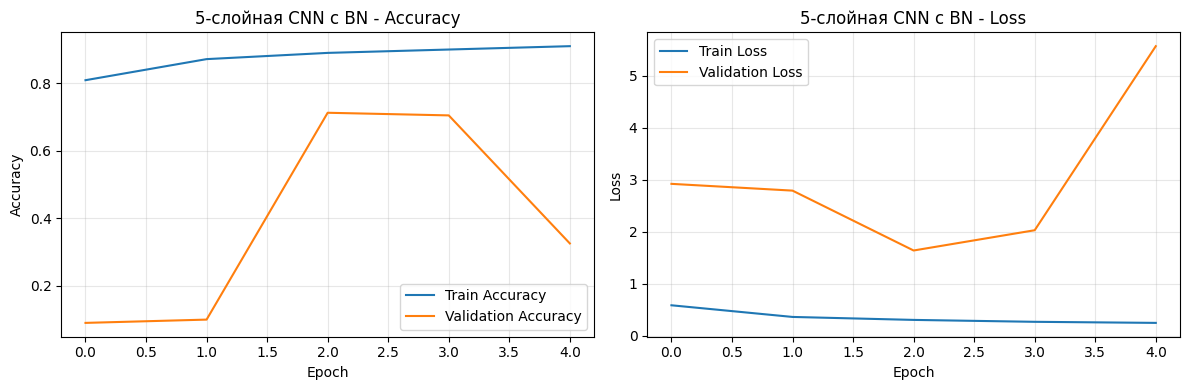


Обучение 10-слойная CNN с BN с BatchNorm...
Epoch 1/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 130s 913ms/step - accuracy: 0.7400 - loss: 0.7990 - val_accuracy: 0.0895 - val_loss: 3.4612
Epoch 2/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 111s 856ms/step - accuracy: 0.8654 - loss: 0.3979 - val_accuracy: 0.6644 - val_loss: 2.5131
Epoch 3/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 111s 859ms/step - accuracy: 0.8780 - loss: 0.3282 - val_accuracy: 0.4981 - val_loss: 1.6198
Epoch 4/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 110s 852ms/step - accuracy: 0.9014 - loss: 0.2832 - val_accuracy: 0.1712 - val_loss: 3.3051
Epoch 5/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 109s 849ms/step - accuracy: 0.8906 - loss: 0.2823 - val_accuracy: 0.6936 - val_loss: 1.1003


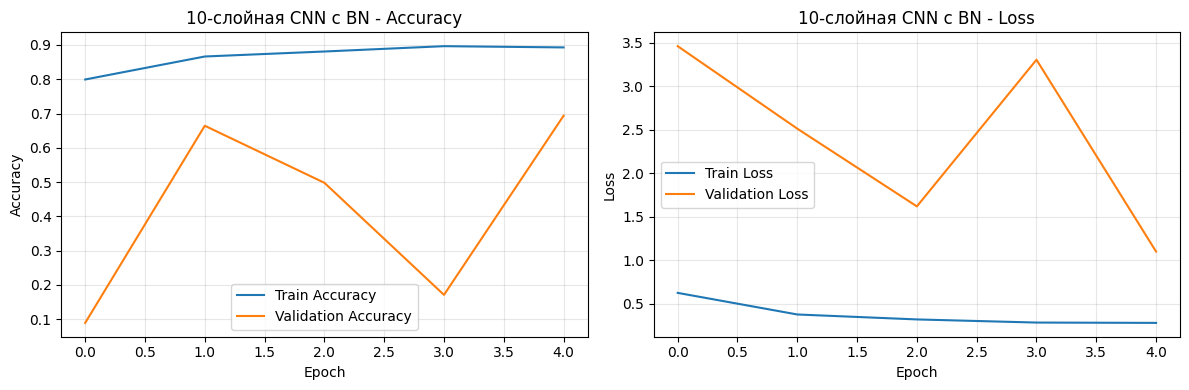

In [41]:
model_3layer_bn = create_3layer_cnn_bn()
model_5layer_bn = create_5layer_cnn_bn()
model_10layer_bn = create_10layer_cnn_bn()

history_3layer_bn, trained_model_3layer_bn = train_and_visualize_bn(
    model_3layer_bn, "3-слойная CNN с BN", train_gen, val_gen, epochs=5
)

history_5layer_bn, trained_model_5layer_bn = train_and_visualize_bn(
    model_5layer_bn, "5-слойная CNN с BN", train_gen, val_gen, epochs=5
)

history_10layer_bn, trained_model_10layer_bn = train_and_visualize_bn(
    model_10layer_bn, "10-слойная CNN с BN", train_gen, val_gen, epochs=5
)


Оценка 3-слойная CNN с BN на тестовых данных...
41/41 ━━━━━━━━━━━━━━━━━━━━ 14s 293ms/step
Accuracy: 0.8067
Precision: 0.8472
Recall: 0.8067
F1-Score: 0.7880

Детальный отчет по классам:
              precision    recall  f1-score   support

     COVID19       0.56      0.97      0.71       116
      NORMAL       0.98      0.39      0.56       317
   PNEUMONIA       0.84      0.94      0.88       855

    accuracy                           0.81      1288
   macro avg       0.79      0.77      0.72      1288
weighted avg       0.85      0.81      0.79      1288



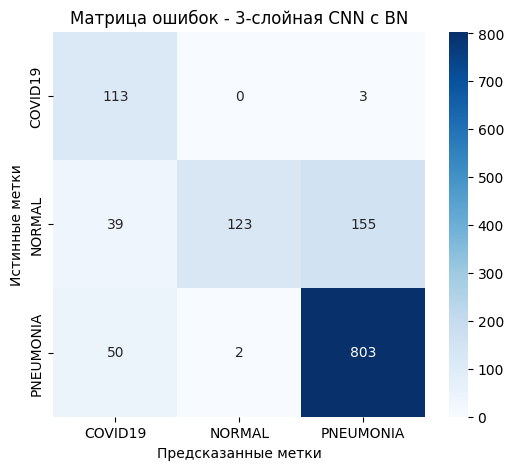


Оценка 5-слойная CNN с BN на тестовых данных...
41/41 ━━━━━━━━━━━━━━━━━━━━ 14s 299ms/step
Accuracy: 0.7283
Precision: 0.5552
Recall: 0.7283
F1-Score: 0.6255

Детальный отчет по классам:
              precision    recall  f1-score   support

     COVID19       0.89      0.73      0.81       116
      NORMAL       0.00      0.00      0.00       317
   PNEUMONIA       0.72      1.00      0.83       855

    accuracy                           0.73      1288
   macro avg       0.54      0.58      0.55      1288
weighted avg       0.56      0.73      0.63      1288



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

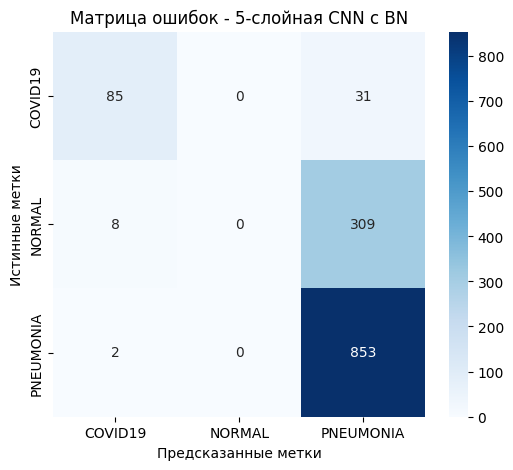


Оценка 10-слойная CNN с BN на тестовых данных...
41/41 ━━━━━━━━━━━━━━━━━━━━ 15s 310ms/step
Accuracy: 0.7065
Precision: 0.7923
Recall: 0.7065
F1-Score: 0.6068

Детальный отчет по классам:
              precision    recall  f1-score   support

     COVID19       0.94      0.41      0.57       116
      NORMAL       1.00      0.02      0.04       317
   PNEUMONIA       0.70      1.00      0.82       855

    accuracy                           0.71      1288
   macro avg       0.88      0.48      0.48      1288
weighted avg       0.79      0.71      0.61      1288



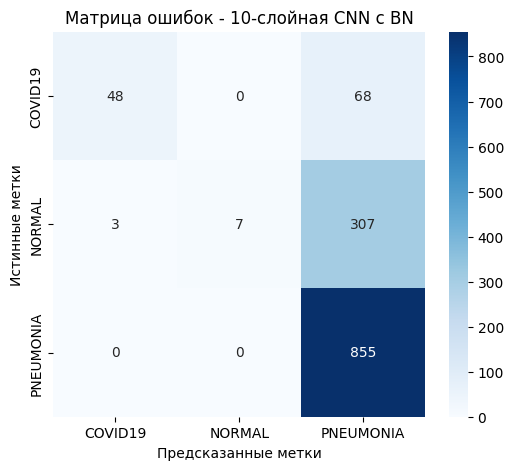


СРАВНЕНИЕ МОДЕЛЕЙ С BATCH NORM И БЕЗ


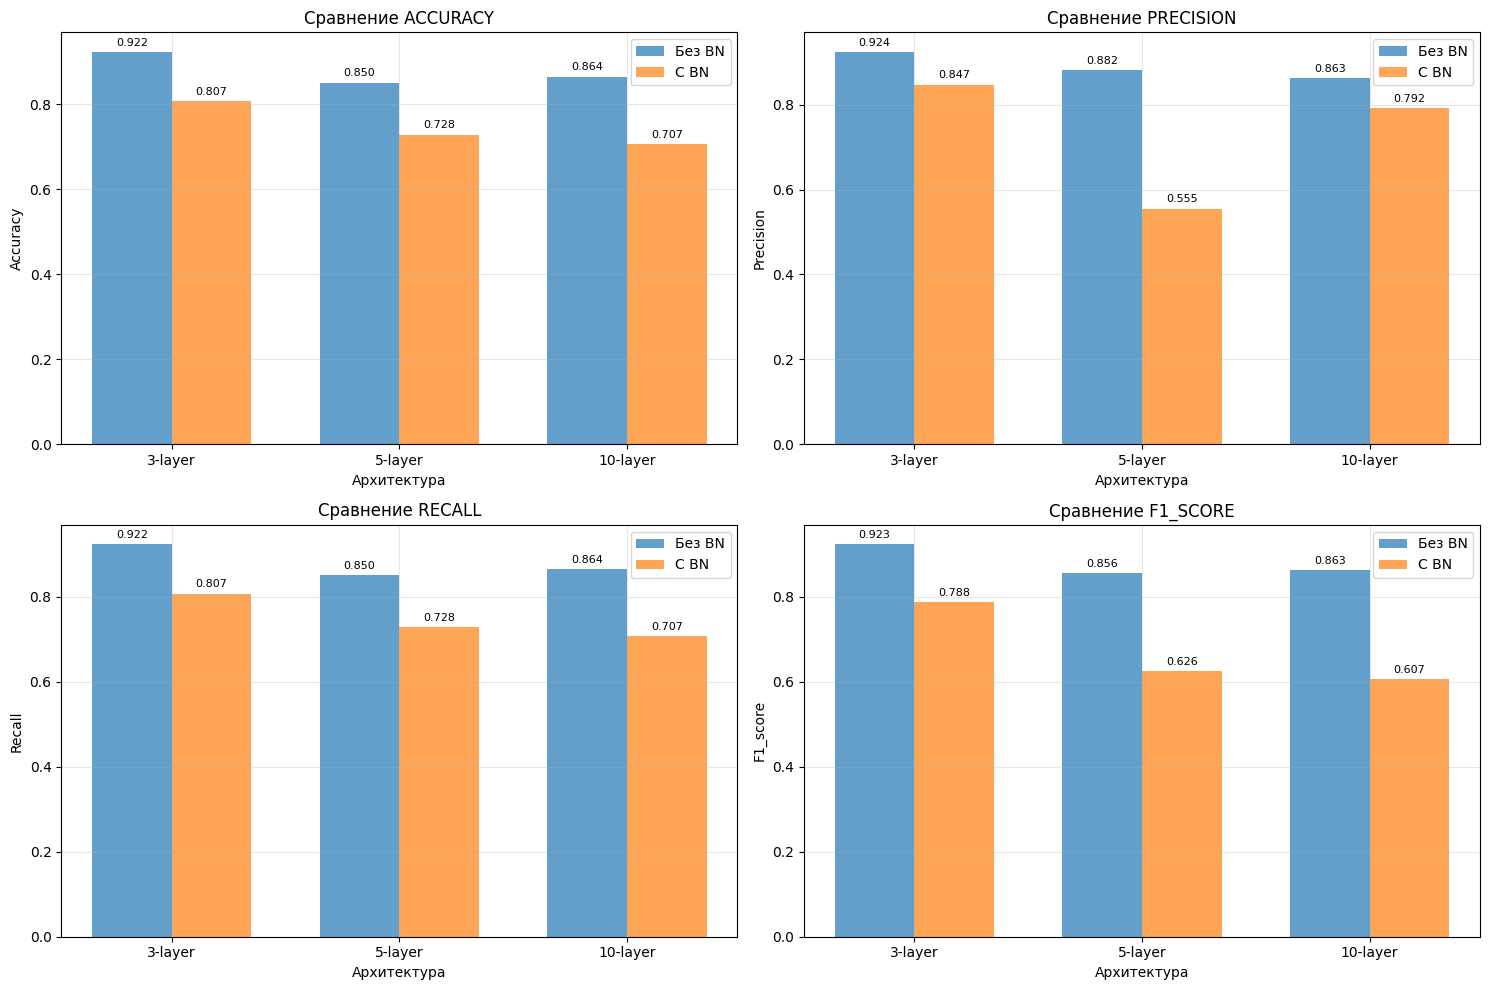

In [42]:
class_names = list(train_gen.class_indices.keys())
results_bn = {}

results_bn['3-layer_bn'] = evaluate_model(trained_model_3layer_bn, test_gen, "3-слойная CNN с BN", class_names)
results_bn['5-layer_bn'] = evaluate_model(trained_model_5layer_bn, test_gen, "5-слойная CNN с BN", class_names)
results_bn['10-layer_bn'] = evaluate_model(trained_model_10layer_bn, test_gen, "10-слойная CNN с BN", class_names)

print("\nСРАВНЕНИЕ МОДЕЛЕЙ С BATCH NORM И БЕЗ")
print("="*50)

results_no_bn = {
    '3-layer': {'accuracy': 0.9224, 'precision': 0.9245, 'recall': 0.9224, 'f1_score': 0.9230},
    '5-layer': {'accuracy': 0.8502, 'precision': 0.8819, 'recall': 0.8502, 'f1_score': 0.8557},
    '10-layer': {'accuracy': 0.8641, 'precision': 0.8632, 'recall': 0.8641, 'f1_score': 0.8628}
}

# Сравнительная визуализация
models_compare = ['3-layer', '5-layer', '10-layer']
metrics = ['accuracy', 'precision', 'recall', 'f1_score']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.ravel()

for idx, metric in enumerate(metrics):
    # Метрики без BN
    values_no_bn = [results_no_bn[model][metric] for model in models_compare]
    # Метрики с BN
    values_bn = [results_bn[model + '_bn'][metric] for model in models_compare]

    x = np.arange(len(models_compare))
    width = 0.35

    bars1 = axes[idx].bar(x - width/2, values_no_bn, width, label='Без BN', alpha=0.7)
    bars2 = axes[idx].bar(x + width/2, values_bn, width, label='С BN', alpha=0.7)

    axes[idx].set_title(f'Сравнение {metric.upper()}')
    axes[idx].set_xlabel('Архитектура')
    axes[idx].set_ylabel(metric.capitalize())
    axes[idx].set_xticks(x)
    axes[idx].set_xticklabels(models_compare)
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

    # Добавляем значения на столбцы
    for bar, value in zip(bars1, values_no_bn):
        axes[idx].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                      f'{value:.3f}', ha='center', va='bottom', fontsize=8)
    for bar, value in zip(bars2, values_bn):
        axes[idx].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                      f'{value:.3f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

##**Задание 6**
Добавьте слои дроп-ауте в созданные ранее архитектуры. Сравните результаты на тестовой выборке.

In [43]:
##ваш код
def create_3layer_cnn_dropout(input_shape=(224, 224, 3), num_classes=3):
    model = keras.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

def create_5layer_cnn_dropout(input_shape=(224, 224, 3), num_classes=3):
    model = keras.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.3),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.3),

        layers.Conv2D(256, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

def create_10layer_cnn_dropout(input_shape=(224, 224, 3), num_classes=3):
    model = keras.Sequential([
        # Блок 1
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.2),

        # Блок 2
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # Блок 3
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.3),

        # Блок 4
        layers.Conv2D(256, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(256, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.4),

        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.6),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.6),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

def train_and_visualize_dropout(model, model_name, train_gen, val_gen, epochs=20):
    print(f"\nОбучение {model_name} с Dropout...")

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=7,
        restore_best_weights=True
    )


    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7
    )

    history = model.fit(
        train_gen,
        epochs=epochs,
        validation_data=val_gen,
        callbacks=[early_stopping, reduce_lr],
        verbose=1
    )

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(history.history['accuracy'], label='Train Accuracy')
    ax1.plot(history.history['val_accuracy'], label='Validation Accuracy')
    ax1.set_title(f'{model_name} - Accuracy')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.plot(history.history['loss'], label='Train Loss')
    ax2.plot(history.history['val_loss'], label='Validation Loss')
    ax2.set_title(f'{model_name} - Loss')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    return history, model

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Обучение 3-слойная CNN с Dropout с Dropout...
Epoch 1/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 124s 895ms/step - accuracy: 0.6020 - loss: 1.0710 - val_accuracy: 0.6644 - val_loss: 8.0502 - learning_rate: 0.0010
Epoch 2/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 124s 964ms/step - accuracy: 0.7939 - loss: 0.5545 - val_accuracy: 0.6770 - val_loss: 12.2445 - learning_rate: 0.0010
Epoch 3/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 107s 831ms/step - accuracy: 0.8345 - loss: 0.4600 - val_accuracy: 0.0973 - val_loss: 4.1080 - learning_rate: 0.0010
Epoch 4/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 108s 837ms/step - accuracy: 0.8387 - loss: 0.4286 - val_accuracy: 0.6644 - val_loss: 39.2300 - learning_rate: 0.0010
Epoch 5/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 107s 824ms/step - accuracy: 0.8452 - loss: 0.3956 - val_accuracy: 0.2763 - val_loss: 2.7217 - learning_rate: 0.0010


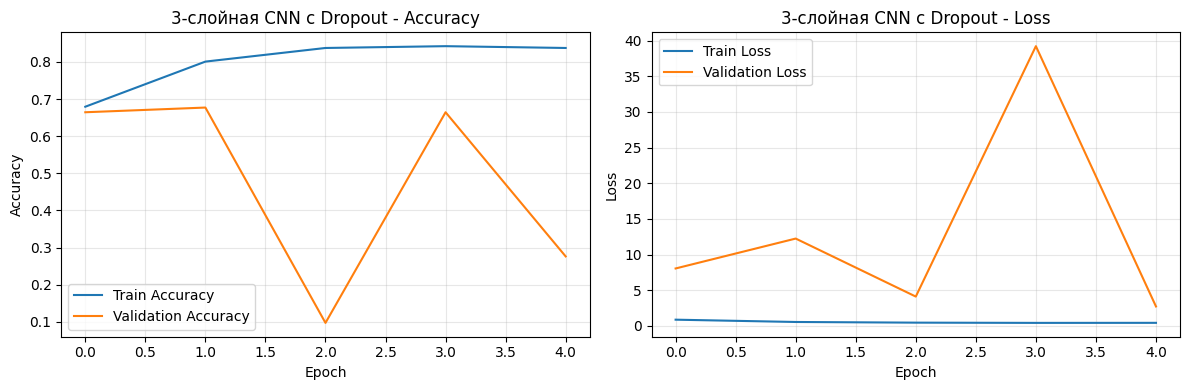


Обучение 5-слойная CNN с Dropout с Dropout...
Epoch 1/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 134s 925ms/step - accuracy: 0.5729 - loss: 1.2676 - val_accuracy: 0.6644 - val_loss: 2.0029 - learning_rate: 0.0010
Epoch 2/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 109s 844ms/step - accuracy: 0.7987 - loss: 0.6058 - val_accuracy: 0.6654 - val_loss: 1.9301 - learning_rate: 0.0010
Epoch 3/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 110s 856ms/step - accuracy: 0.8235 - loss: 0.5109 - val_accuracy: 0.6644 - val_loss: 2.2845 - learning_rate: 0.0010
Epoch 4/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 111s 859ms/step - accuracy: 0.8653 - loss: 0.3601 - val_accuracy: 0.6975 - val_loss: 2.5776 - learning_rate: 0.0010
Epoch 5/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 130s 1s/step - accuracy: 0.8700 - loss: 0.3599 - val_accuracy: 0.7111 - val_loss: 2.2033 - learning_rate: 0.0010


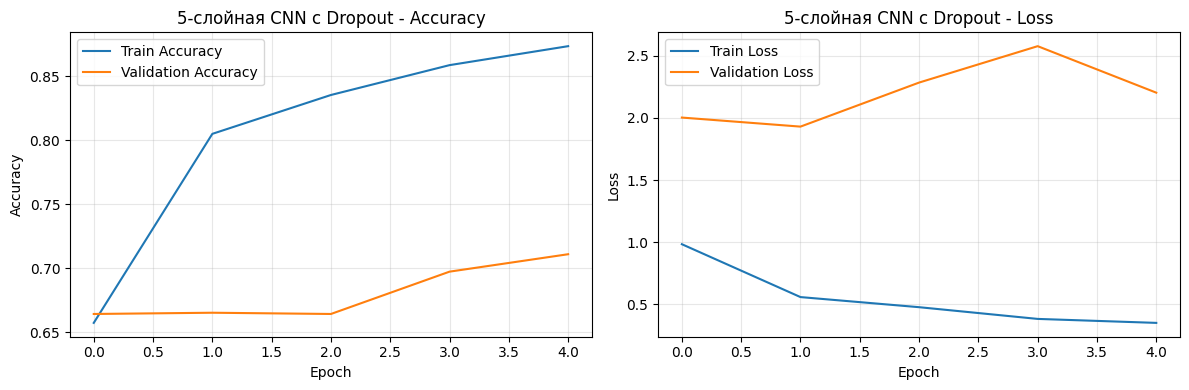


Обучение 10-слойная CNN с Dropout с Dropout...
Epoch 1/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 143s 973ms/step - accuracy: 0.4684 - loss: 1.4995 - val_accuracy: 0.6644 - val_loss: 1.1587 - learning_rate: 0.0010
Epoch 2/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 113s 874ms/step - accuracy: 0.7054 - loss: 0.8372 - val_accuracy: 0.6644 - val_loss: 1.9963 - learning_rate: 0.0010
Epoch 3/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 112s 870ms/step - accuracy: 0.7809 - loss: 0.6154 - val_accuracy: 0.7014 - val_loss: 1.2068 - learning_rate: 0.0010
Epoch 4/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 112s 866ms/step - accuracy: 0.8076 - loss: 0.5210 - val_accuracy: 0.2490 - val_loss: 3.1538 - learning_rate: 0.0010
Epoch 5/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 112s 866ms/step - accuracy: 0.8490 - loss: 0.4246 - val_accuracy: 0.8589 - val_loss: 0.3724 - learning_rate: 2.0000e-04


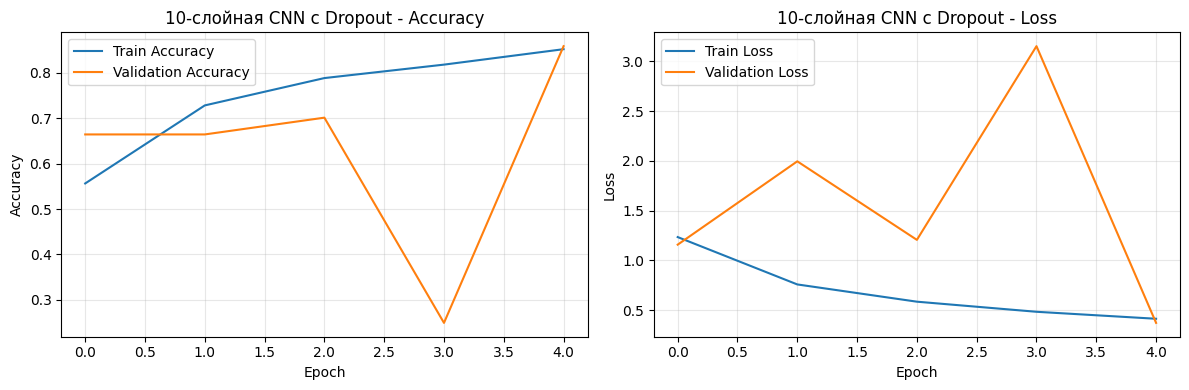

In [44]:
model_3layer_dropout = create_3layer_cnn_dropout()
model_5layer_dropout = create_5layer_cnn_dropout()
model_10layer_dropout = create_10layer_cnn_dropout()

history_3layer_dropout, trained_model_3layer_dropout = train_and_visualize_dropout(
    model_3layer_dropout, "3-слойная CNN с Dropout", train_gen, val_gen, epochs=5
)

history_5layer_dropout, trained_model_5layer_dropout = train_and_visualize_dropout(
    model_5layer_dropout, "5-слойная CNN с Dropout", train_gen, val_gen, epochs=5
)

history_10layer_dropout, trained_model_10layer_dropout = train_and_visualize_dropout(
    model_10layer_dropout, "10-слойная CNN с Dropout", train_gen, val_gen, epochs=5
)


Оценка 3-слойная CNN с Dropout на тестовых данных...
41/41 ━━━━━━━━━━━━━━━━━━━━ 14s 285ms/step
Accuracy: 0.2896
Precision: 0.2627
Recall: 0.2896
F1-Score: 0.1444

Детальный отчет по классам:
              precision    recall  f1-score   support

     COVID19       0.28      0.48      0.35       116
      NORMAL       0.29      1.00      0.45       317
   PNEUMONIA       0.25      0.00      0.00       855

    accuracy                           0.29      1288
   macro avg       0.27      0.49      0.27      1288
weighted avg       0.26      0.29      0.14      1288



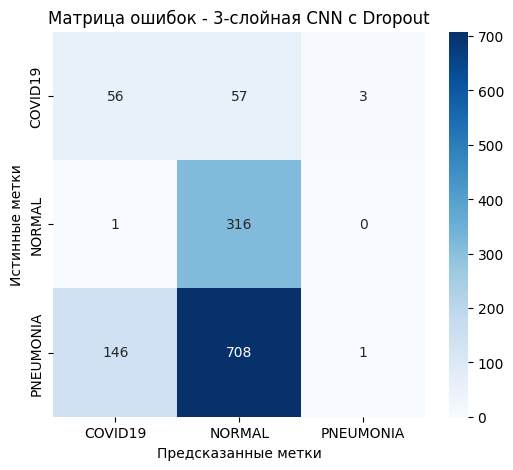


Оценка 5-слойная CNN с Dropout на тестовых данных...
41/41 ━━━━━━━━━━━━━━━━━━━━ 14s 298ms/step
Accuracy: 0.6677
Precision: 0.5128
Recall: 0.6677
F1-Score: 0.5408

Детальный отчет по классам:
              precision    recall  f1-score   support

     COVID19       0.78      0.06      0.11       116
      NORMAL       0.00      0.00      0.00       317
   PNEUMONIA       0.67      1.00      0.80       855

    accuracy                           0.67      1288
   macro avg       0.48      0.35      0.30      1288
weighted avg       0.51      0.67      0.54      1288



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

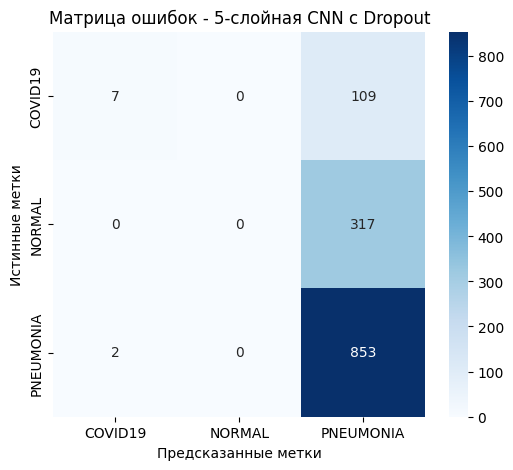


Оценка 10-слойная CNN с Dropout на тестовых данных...
41/41 ━━━━━━━━━━━━━━━━━━━━ 15s 312ms/step
Accuracy: 0.8742
Precision: 0.8891
Recall: 0.8742
F1-Score: 0.8771

Детальный отчет по классам:
              precision    recall  f1-score   support

     COVID19       0.97      0.75      0.84       116
      NORMAL       0.72      0.90      0.80       317
   PNEUMONIA       0.94      0.88      0.91       855

    accuracy                           0.87      1288
   macro avg       0.88      0.84      0.85      1288
weighted avg       0.89      0.87      0.88      1288



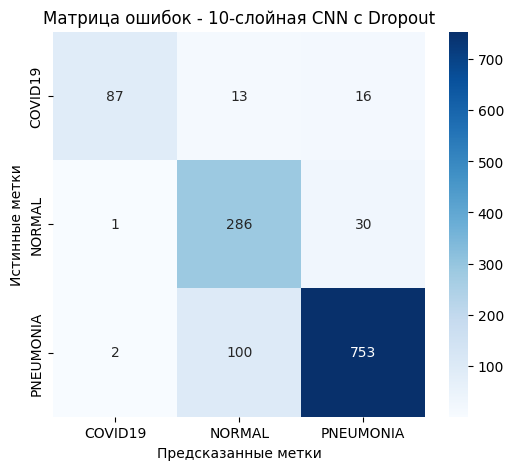

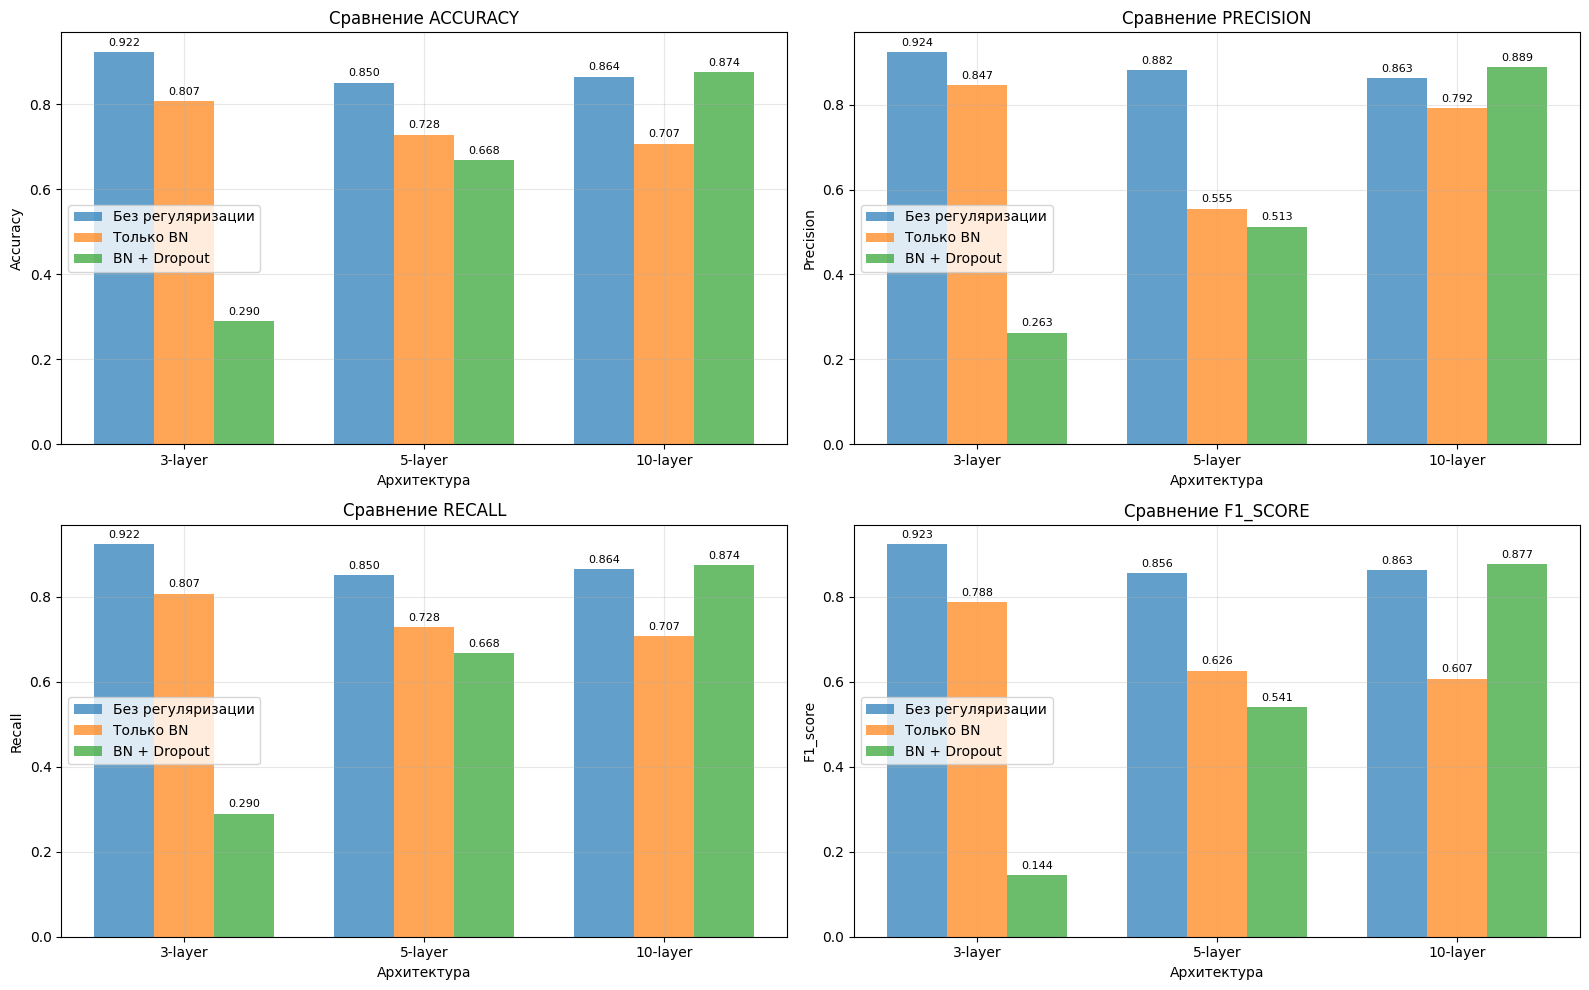

In [45]:
class_names = list(train_gen.class_indices.keys())
results_dropout = {}

results_dropout['3-layer_dropout'] = evaluate_model(
    trained_model_3layer_dropout, test_gen, "3-слойная CNN с Dropout", class_names
)

results_dropout['5-layer_dropout'] = evaluate_model(
    trained_model_5layer_dropout, test_gen, "5-слойная CNN с Dropout", class_names
)

results_dropout['10-layer_dropout'] = evaluate_model(
    trained_model_10layer_dropout, test_gen, "10-слойная CNN с Dropout", class_names
)

results_no_reg = {
    '3-layer': {'accuracy': 0.9224, 'precision': 0.9245, 'recall': 0.9224, 'f1_score': 0.9230},
    '5-layer': {'accuracy': 0.8502, 'precision': 0.8819, 'recall': 0.8502, 'f1_score': 0.8557},
    '10-layer': {'accuracy': 0.8641, 'precision': 0.8632, 'recall': 0.8641, 'f1_score': 0.8628}
}

results_bn = {
    '3-layer_bn': {'accuracy': 0.807, 'precision': 0.847, 'recall': 0.807, 'f1_score': 0.788},
    '5-layer_bn': {'accuracy': 0.728, 'precision': 0.555, 'recall': 0.728, 'f1_score': 0.626},
    '10-layer_bn': {'accuracy': 0.707, 'precision': 0.792, 'recall': 0.707, 'f1_score': 0.607}
}

# Сравнительная визуализация всех подходов
models_compare = ['3-layer', '5-layer', '10-layer']
metrics = ['accuracy', 'precision', 'recall', 'f1_score']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.ravel()

for idx, metric in enumerate(metrics):
    # Метрики для всех трех подходов
    values_no_reg = [results_no_reg[model][metric] for model in models_compare]
    values_bn = [results_bn[model + '_bn'][metric] for model in models_compare]
    values_dropout = [results_dropout[model + '_dropout'][metric] for model in models_compare]

    x = np.arange(len(models_compare))
    width = 0.25

    bars1 = axes[idx].bar(x - width, values_no_reg, width, label='Без регуляризации', alpha=0.7)
    bars2 = axes[idx].bar(x, values_bn, width, label='Только BN', alpha=0.7)
    bars3 = axes[idx].bar(x + width, values_dropout, width, label='BN + Dropout', alpha=0.7)

    axes[idx].set_title(f'Сравнение {metric.upper()}')
    axes[idx].set_xlabel('Архитектура')
    axes[idx].set_ylabel(metric.capitalize())
    axes[idx].set_xticks(x)
    axes[idx].set_xticklabels(models_compare)
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

    # Добавляем значения на столбцы
    for bar, value in zip(bars1, values_no_reg):
        axes[idx].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                      f'{value:.3f}', ha='center', va='bottom', fontsize=8)
    for bar, value in zip(bars2, values_bn):
        axes[idx].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                      f'{value:.3f}', ha='center', va='bottom', fontsize=8)
    for bar, value in zip(bars3, values_dropout):
        axes[idx].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                      f'{value:.3f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

##**Задание 7**
Реализуйте трансферное обучение любыми двумя глубокими моделями, например, VGG-16 и ResNet-50. Сравните результаты на тестовой выборке. Сделайте визуализации нескольких изображений с подписями реальной и прогнозной меток.

In [46]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, precision_recall_fscore_support
import seaborn as sns

In [47]:
##ваш код
# Функция для создания модели на основе VGG-16
def create_vgg16_model(input_shape=(224, 224, 3), num_classes=3):

    # Загрузка предобученной VGG-16 без верхних слоев
    base_model = keras.applications.VGG16(
        weights='imagenet',
        include_top=False,
        input_shape=input_shape
    )

    # Заморозка базовых слоев
    base_model.trainable = False

    # Добавление новых слоев для классификации
    model = keras.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ])

    return model

# Функция для создания модели на основе ResNet-50
def create_resnet50_model(input_shape=(224, 224, 3), num_classes=3):

    # Загрузка предобученной ResNet-50 без верхних слоев
    base_model = keras.applications.ResNet50(
        weights='imagenet',
        include_top=False,
        input_shape=input_shape
    )

    # Заморозка базовых слоев
    base_model.trainable = False

    # Добавление новых слоев для классификации
    model = keras.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ])

    return model

# Функция для обучения моделей трансферного обучения
def train_transfer_model(model, model_name, train_gen, val_gen, epochs=5):

    # Компиляция с более низким learning rate
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    # Callbacks
    early_stopping = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    reduce_lr = keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7
    )

    history = model.fit(
        train_gen,
        epochs=epochs,
        validation_data=val_gen,
        callbacks=[early_stopping, reduce_lr],
        verbose=1
    )

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(history.history['accuracy'], label='Train Accuracy')
    ax1.plot(history.history['val_accuracy'], label='Validation Accuracy')
    ax1.set_title(f'{model_name} - Accuracy')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.plot(history.history['loss'], label='Train Loss')
    ax2.plot(history.history['val_loss'], label='Validation Loss')
    ax2.set_title(f'{model_name} - Loss')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    return history, model


Архитектура VGG-16:


Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_51 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_70          │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_52 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_71          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_53 (Dense)                │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,112,515 (57.65 MB)

 Trainable params: 396,291 (1.51 MB)

 Non-trainable params: 14,716,224 (56.14 MB)

... (3 outputs left out)

 Total params: 24,705,411 (94.24 MB)

 Trainable params: 1,116,419 (4.26 MB)

 Non-trainable params: 23,588,992 (89.98 MB)


Epoch 1/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 134s 989ms/step - accuracy: 0.4985 - loss: 1.3025 - val_accuracy: 0.7967 - val_loss: 0.8316 - learning_rate: 1.0000e-04
Epoch 2/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 111s 865ms/step - accuracy: 0.7084 - loss: 0.8262 - val_accuracy: 0.8278 - val_loss: 0.6218 - learning_rate: 1.0000e-04
Epoch 3/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 112s 872ms/step - accuracy: 0.7723 - loss: 0.6436 - val_accuracy: 0.8940 - val_loss: 0.4746 - learning_rate: 1.0000e-04
Epoch 4/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 112s 868ms/step - accuracy: 0.7885 - loss: 0.5899 - val_accuracy: 0.9076 - val_loss: 0.3167 - learning_rate: 1.0000e-04
Epoch 5/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 112s 870ms/step - accuracy: 0.8333 - loss: 0.4764 - val_accuracy: 0.9115 - val_loss: 0.3200 - learning_rate: 1.0000e-04


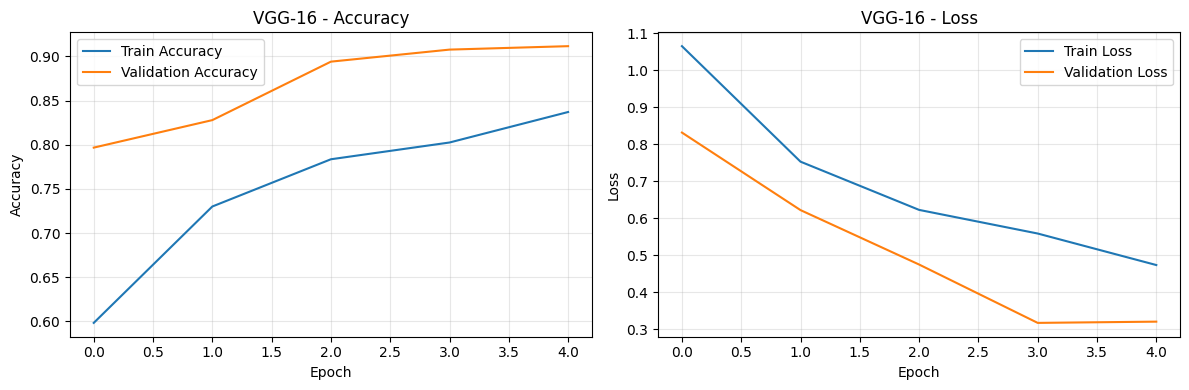


Epoch 1/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 137s 943ms/step - accuracy: 0.4600 - loss: 1.3725 - val_accuracy: 0.6625 - val_loss: 0.9835 - learning_rate: 1.0000e-04
Epoch 2/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 108s 836ms/step - accuracy: 0.6116 - loss: 1.0125 - val_accuracy: 0.6848 - val_loss: 0.7562 - learning_rate: 1.0000e-04
Epoch 3/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 108s 839ms/step - accuracy: 0.6505 - loss: 0.9100 - val_accuracy: 0.5885 - val_loss: 0.8528 - learning_rate: 1.0000e-04
Epoch 4/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 109s 843ms/step - accuracy: 0.6832 - loss: 0.8416 - val_accuracy: 0.6644 - val_loss: 1.0970 - learning_rate: 1.0000e-04
Epoch 5/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 107s 829ms/step - accuracy: 0.7218 - loss: 0.7661 - val_accuracy: 0.6693 - val_loss: 0.7791 - learning_rate: 1.0000e-04


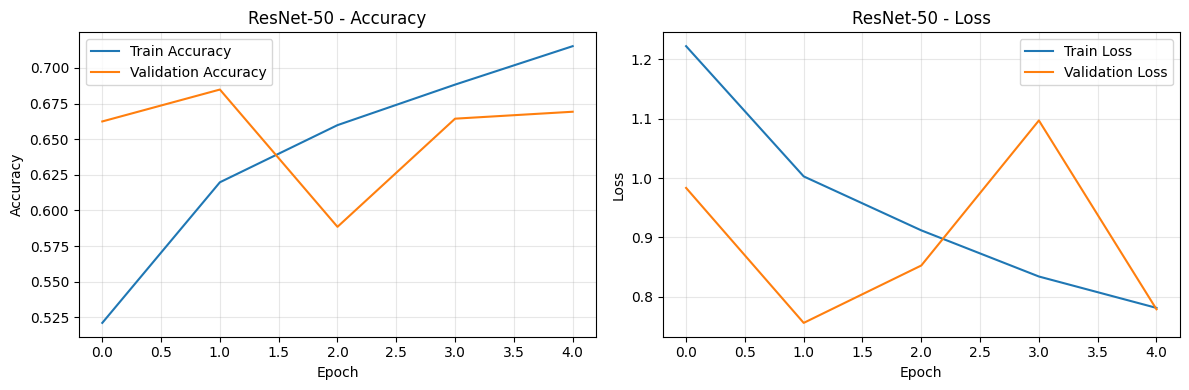


Оценка VGG-16 на тестовых данных...
41/41 ━━━━━━━━━━━━━━━━━━━━ 19s 421ms/step
Accuracy: 0.8789
Precision: 0.8952
Recall: 0.8789
F1-Score: 0.8810

Детальный отчет по классам:
              precision    recall  f1-score   support

     COVID19       0.99      0.69      0.81       116
      NORMAL       0.72      0.92      0.81       317
   PNEUMONIA       0.95      0.89      0.92       855

    accuracy                           0.88      1288
   macro avg       0.89      0.83      0.85      1288
weighted avg       0.90      0.88      0.88      1288



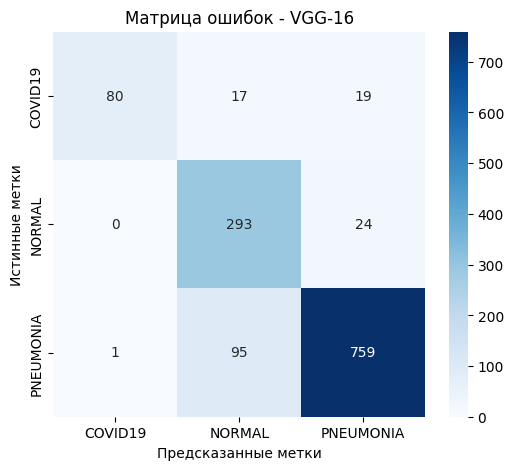


Оценка ResNet-50 на тестовых данных...
41/41 ━━━━━━━━━━━━━━━━━━━━ 24s 437ms/step
Accuracy: 0.7329
Precision: 0.6842
Recall: 0.7329
F1-Score: 0.6716

Детальный отчет по классам:
              precision    recall  f1-score   support

     COVID19       0.00      0.00      0.00       116
      NORMAL       0.83      0.35      0.49       317
   PNEUMONIA       0.72      0.97      0.83       855

    accuracy                           0.73      1288
   macro avg       0.52      0.44      0.44      1288
weighted avg       0.68      0.73      0.67      1288



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

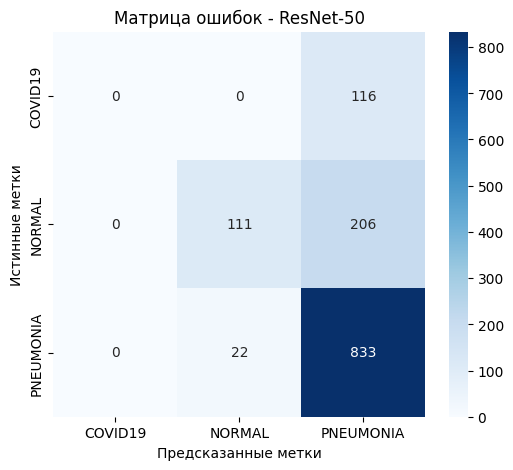

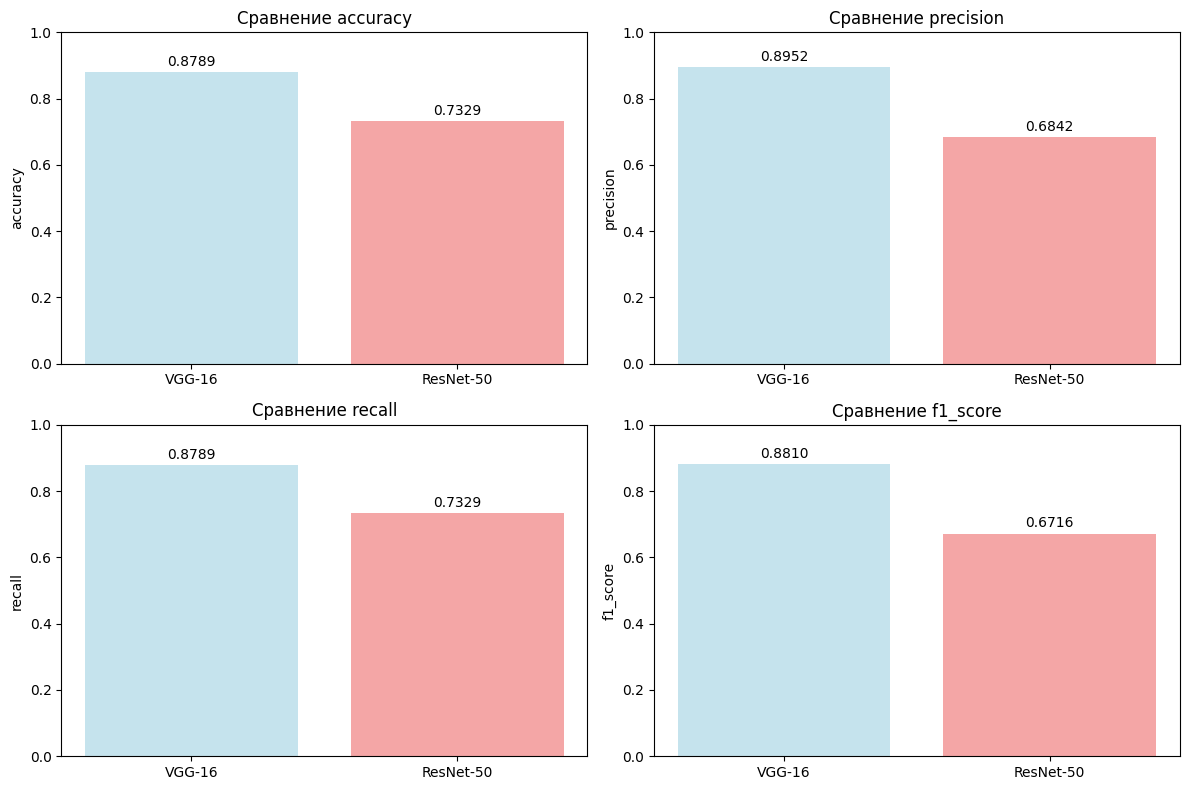


Визуализация предсказаний VGG-16:
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


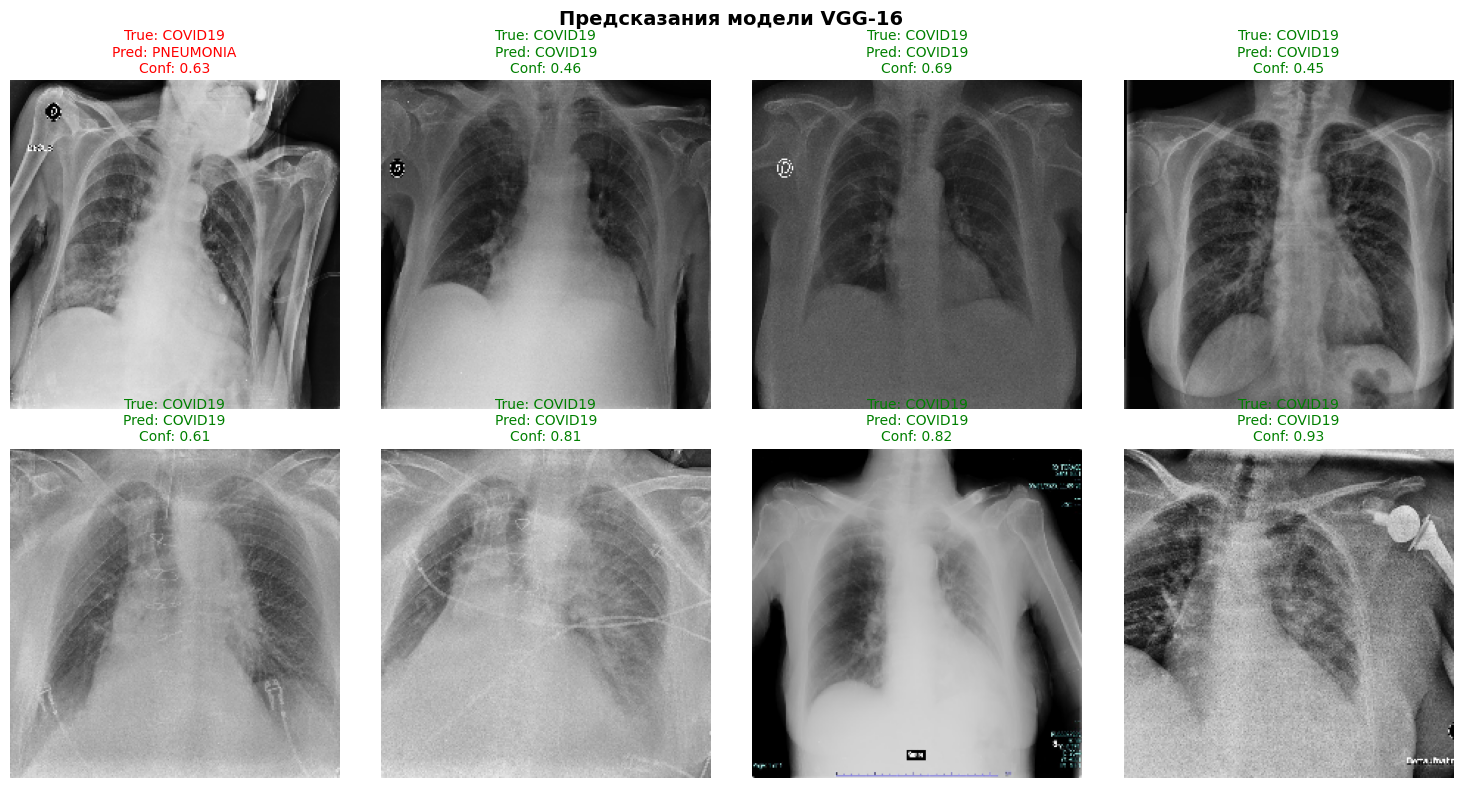

Точность на 32 изображениях: 0.688

Визуализация предсказаний ResNet-50:
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


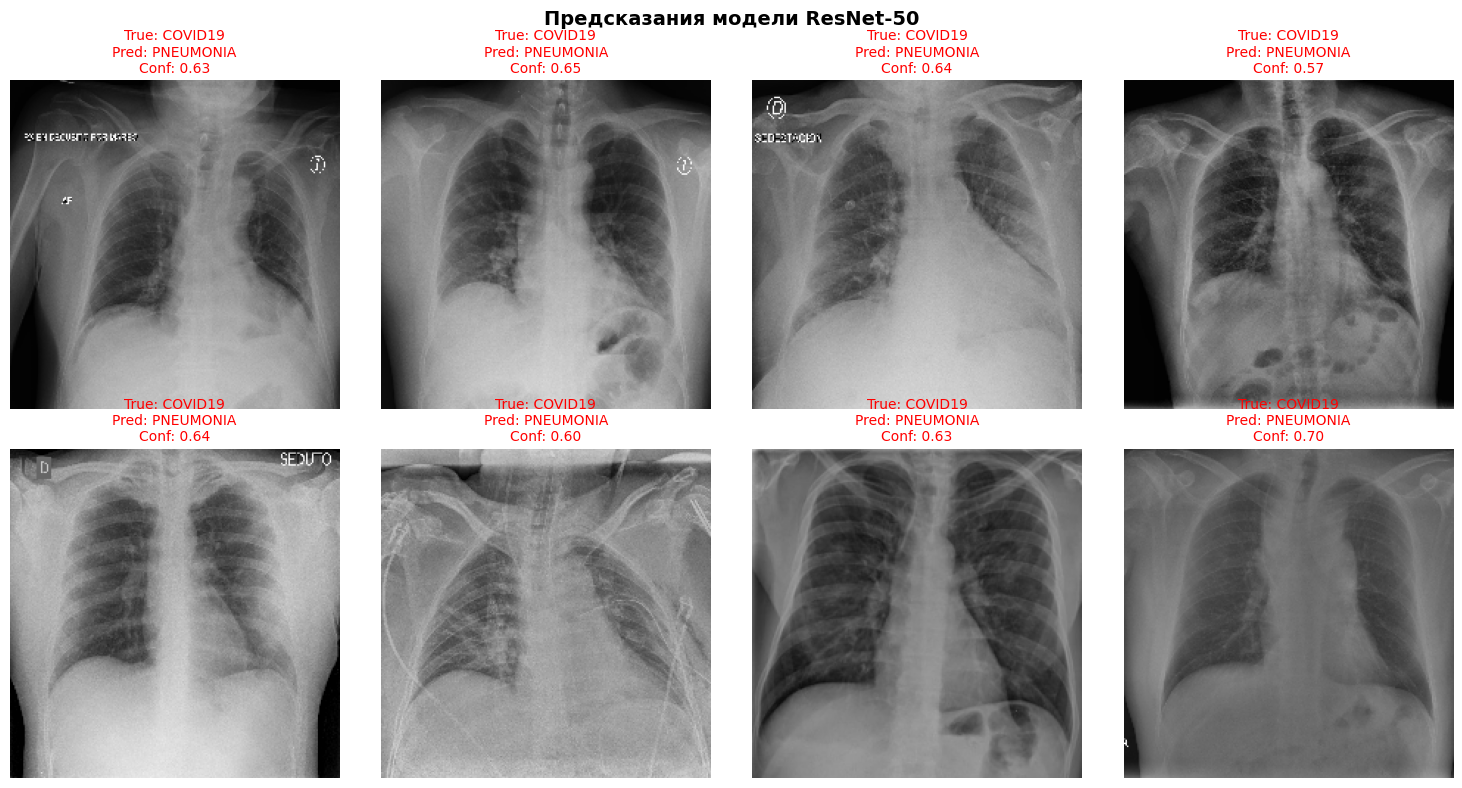

Точность на 32 изображениях: 0.000


In [49]:
# Создаем модели
vgg16_model = create_vgg16_model()
resnet50_model = create_resnet50_model()

print("\nАрхитектура VGG-16:")
vgg16_model.summary()

print("\nАрхитектура ResNet-50:")
resnet50_model.summary()

# Обучение VGG-16
print("\n" + "="*40)
history_vgg16, trained_vgg16 = train_transfer_model(
    vgg16_model, "VGG-16", train_gen, val_gen, epochs=5
)

# Обучение ResNet-50
print("\n" + "="*40)
history_resnet50, trained_resnet50 = train_transfer_model(
    resnet50_model, "ResNet-50", train_gen, val_gen, epochs=5
)

# Оценка моделей на тестовых данных
class_names = list(train_gen.class_indices.keys())
results_transfer = {}

# Оценка VGG-16
results_transfer['VGG-16'] = evaluate_model(
    trained_vgg16, test_gen, "VGG-16", class_names
)

# Оценка ResNet-50
results_transfer['ResNet-50'] = evaluate_model(
    trained_resnet50, test_gen, "ResNet-50", class_names
)

# Сравнение моделей трансферного обучения

# Сравнительная визуализация метрик
models_transfer = ['VGG-16', 'ResNet-50']
metrics = ['accuracy', 'precision', 'recall', 'f1_score']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for idx, metric in enumerate(metrics):
    values = [results_transfer[model][metric] for model in models_transfer]

    bars = axes[idx].bar(models_transfer, values, color=['lightblue', 'lightcoral'], alpha=0.7)
    axes[idx].set_title(f'Сравнение {metric}')
    axes[idx].set_ylabel(metric)
    axes[idx].set_ylim(0, 1)

    for bar, value in zip(bars, values):
        height = bar.get_height()
        axes[idx].text(bar.get_x() + bar.get_width()/2, height + 0.01,
                     f'{value:.4f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

# Визуализация предсказаний на нескольких изображениях
def visualize_predictions(model, test_gen, model_name, num_images=8):
    # Получаем батч изображений
    test_images, test_labels = next(test_gen)

    # Предсказания
    predictions = model.predict(test_images)
    predicted_classes = np.argmax(predictions, axis=1)
    true_classes = np.argmax(test_labels, axis=1)

    # Визуализация
    fig, axes = plt.subplots(2, 4, figsize=(15, 8))
    axes = axes.ravel()

    for i in range(min(num_images, len(test_images))):
        # Отображаем изображение
        axes[i].imshow(test_images[i])

        # Получаем метки
        true_label = class_names[true_classes[i]]
        pred_label = class_names[predicted_classes[i]]
        confidence = np.max(predictions[i])

        # Определяем цвет текста
        color = 'green' if true_label == pred_label else 'red'

        # Добавляем подписи
        axes[i].set_title(f'True: {true_label}\nPred: {pred_label}\nConf: {confidence:.2f}',
                         color=color, fontsize=10)
        axes[i].axis('off')

    plt.suptitle(f'Предсказания модели {model_name}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Статистика по предсказаниям
    correct_predictions = np.sum(predicted_classes == true_classes)
    total_predictions = len(predicted_classes)
    accuracy = correct_predictions / total_predictions

    print(f"Точность на {total_predictions} изображениях: {accuracy:.3f}")

# Визуализация предсказаний для VGG-16
print("\nВизуализация предсказаний VGG-16:")
visualize_predictions(trained_vgg16, test_gen, "VGG-16")

# Визуализация предсказаний для ResNet-50
print("\nВизуализация предсказаний ResNet-50:")
visualize_predictions(trained_resnet50, test_gen, "ResNet-50")


##**Выводы:**

In [ ]:
##ваши выводы

3-слойная CNN (F1: 0.9230) - лучшая производительность

VGG-16 (F1: 0.8810) - лучшая среди трансферных моделей

10-слойная с Dropout (F1: 0.8771) - лучшая регуляризованная

##**Допзадание**
Исследуйте туториал по обработке серии медицинских снимков с помощью трехмерных сверточных нейронных сетей (https://github.com/hasibzunair/3D-image-classification-tutorial/blob/master/3D_image_classification.ipynb)